### AIS Nordsee – Validierung selbst gemeldeter Schiffstypen mittels Unsupervised Learning

Workflow-Schritte:
1. Problemstellung
2. Datenerhebung
3. Exploration und Visualisierung
4. Train/Test Split
5. Cleaning und Preprocessing
6. Feature Engineering und Feature Selection
7. Modellierung und Hyperparameter-Tuning
8. Evaluation
9. Interpretation

**Ausgangslage:** Im AIS-System (Automatic Identification System) wird der Schiffstyp manuell
von der Besatzung über das sogenannte MKD (Minimum Keyboard Display) eingetragen. Im Gegensatz
zu Position oder Geschwindigkeit, die automatisch per GPS/Sensoren erfasst werden, sind diese
statischen Daten fehleranfällig – ob durch Eingabefehler oder absichtliche Manipulation.

**Forschungsfrage:** Kann man anhand des tatsächlichen Verhaltens (Geschwindigkeit, Kurs,
Navigationsstatus, Schiffsgröße) erkennen, ob der gemeldete Schiffstyp plausibel ist?

**Ansatz:** Drei Unsupervised-Learning-Methoden gruppieren Schiffe nach Verhaltensdaten.
Stimmt das Cluster nicht mit dem gemeldeten Typ überein, wird das Schiff als auffällig markiert.

0 — Setup: Imports und Einstellungen

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.stats import spearmanr

1 — Problemstellung

Der Schiffstyp im AIS-System wird manuell von der Besatzung eingetragen, über das sogenannte
MKD (Minimum Keyboard Display). Anders als Position oder Geschwindigkeit, die automatisch per
GPS kommen, kann der Typ also falsch sein — Tippfehler, alte Einstellungen, oder im schlimmsten
Fall absichtlich falsch (z.B. ein Fischer der sich als Cargo tarnt um Fangquoten zu umgehen).

**Forschungsfrage:** Können wir anhand des tatsächlichen Fahrverhaltens erkennen, ob der
gemeldete Schiffstyp plausibel ist?

Supervised Learning geht hier nicht, weil die Labels (= die gemeldeten Typen) ja genau das sind
was wir anzweifeln. Also Unsupervised: Cluster bilden, dann gucken ob die zu den Typen passen.

**Wichtig: Pure Unsupervised Ansatz.** Der gemeldete Schiffstyp fließt zu keinem Zeitpunkt
als Feature in die Modelle ein. Clustering und Anomalieerkennung arbeiten ausschließlich mit
Verhaltens- und Physikdaten (Geschwindigkeit, Größe, Tiefgang, Kurs, Position). Der gemeldete
Typ wird nur am Anfang zum Einschränken des Scopes und am Ende zur Validierung der
Ergebnisse genutzt.

Drei Methoden:
- K-Means
- DBSCAN
- Isolation Forest (baut auf Decision Trees auf)

2 — Datenerhebung

- AIS-Daten der dänischen Seefahrtsbehörde (aisdk_2026_nordsee_500k.csv)
- 500.000 AIS-Signale aus der Nordsee
- Externe Hafendaten (nordseehaefen.csv) für Feature Engineering

In [2]:
# Load Dataset
df = pd.read_csv('aisdk_2026_nordsee_500k.csv')
print(f'Datensatz geladen: {len(df)} Zeilen, {df.shape[1]} Spalten')
df.head()

Datensatz geladen: 500000 Zeilen, 26 Spalten


,# Timestamp,Type of mobile,MMSI,Latitude,Longitude,Navigational status,ROT,SOG,COG,Heading,...,Length,Type of position fixing device,Draught,Destination,ETA,Data source type,A,B,C,D
0,01/01/2026 00:00:00,Class A,219014162,91.0,0.0,Unknown value,NaN,NaN,NaN,NaN,...,10.0,Internal,1.4,VIGSOE,01/01/2026 00:00:00,AIS,4.0,6.0,2.0,2.0
1,01/01/2026 00:00:00,Class A,219904000,91.0,0.0,Unknown value,NaN,NaN,NaN,NaN,...,18.0,GPS,2.5,HJEM TIL KATE,26/10/2026 00:00:00,AIS,15.0,3.0,1.0,4.0
2,01/01/2026 00:00:00,Class A,219904000,91.0,0.0,Unknown value,NaN,NaN,NaN,NaN,...,18.0,GPS,2.5,HJEM TIL KATE,26/10/2026 00:00:00,AIS,15.0,3.0,1.0,4.0
3,01/01/2026 00:00:00,Class A,219904000,91.0,0.0,Unknown value,NaN,NaN,NaN,NaN,...,18.0,GPS,2.5,HJEM TIL KATE,26/10/2026 00:00:00,AIS,15.0,3.0,1.0,4.0
4,01/01/2026 00:00:01,Class A,219023274,91.0,0.0,Unknown value,NaN,NaN,NaN,NaN,...,16.0,GPS,NaN,Unknown,NaN,AIS,12.0,4.0,2.0,3.0


3 — Exploration und Visualisierung

In [3]:
# Datensatz-Überblick
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   # Timestamp                     500000 non-null  str    
 1   Type of mobile                  500000 non-null  str    
 2   MMSI                            500000 non-null  int64  
 3   Latitude                        500000 non-null  float64
 4   Longitude                       500000 non-null  float64
 5   Navigational status             500000 non-null  str    
 6   ROT                             399975 non-null  float64
 7   SOG                             497223 non-null  float64
 8   COG                             457988 non-null  float64
 9   Heading                         426288 non-null  float64
 10  IMO                             500000 non-null  str    
 11  Callsign                        500000 non-null  str    
 12  Name                       

,MMSI,Latitude,Longitude,ROT,SOG,COG,Heading,Width,Length,Draught,A,B,C,D
count,5.000000e+05,500000.000000,500000.000000,399975.000000,497223.000000,457988.000000,426288.000000,500000.000000,500000.000000,384834.000000,499188.000000,494560.000000,495271.000000,495212.000000
mean,2.631650e+08,56.463741,10.782436,0.009373,4.259775,179.773328,178.269109,13.965026,76.711058,5.071107,51.304288,25.770471,7.041668,7.057541
std,9.873532e+07,2.064219,1.800446,3.690653,5.872556,107.927201,103.384788,10.858508,75.726537,2.968739,60.185122,37.736972,6.265916,6.160292
min,1.190002e+08,28.354808,-6.006455,-446.400000,0.000000,0.000000,0.000000,1.000000,2.000000,0.100000,1.000000,1.000000,1.000000,1.000000
25%,2.190102e+08,55.461693,9.932413,0.000000,0.000000,70.800000,76.000000,6.000000,17.000000,2.600000,10.000000,7.000000,3.000000,3.000000
50%,2.198530e+08,56.409322,10.806548,0.000000,0.000000,192.000000,183.000000,11.000000,38.000000,5.000000,19.000000,13.000000,4.000000,5.000000
75%,2.610077e+08,57.492700,11.792765,0.000000,10.000000,268.400000,260.000000,19.000000,118.000000,6.900000,79.000000,27.000000,10.000000,9.000000
max,6.770641e+08,91.000000,20.674300,361.600000,55.900000,359.900000,359.000000,106.000000,557.000000,25.500000,509.000000,330.000000,61.000000,51.000000


In [4]:
# Fehlende Werte pro Spalte
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'Fehlend': missing, '%': missing_pct})
print(missing_df[missing_df['Fehlend'] > 0])

             Fehlend     %
Cargo type    418171  83.6
ETA           170122  34.0
Draught       115166  23.0
ROT           100025  20.0
Heading        73712  14.7
COG            42012   8.4
B               5440   1.1
D               4788   1.0
C               4729   0.9
SOG             2777   0.6
A                812   0.2
Name             311   0.1
Destination      101   0.0


In [5]:
# Ungültige Werte prüfen
print('=== Ungültige Werte ===')

# Latitude 91.0 = AIS-Standardwert wenn kein GPS-Signal
lat91 = (df['Latitude'] == 91.0).sum()
print(f'Latitude == 91.0 (kein GPS-Signal): {lat91} ({lat91/len(df)*100:.1f}%)')

# Positionen außerhalb der Nordsee
outside = ((df['Latitude'] < 50) | (df['Latitude'] > 62) | (df['Longitude'] < -5) | (df['Longitude'] > 12)).sum()
print(f'Positionen außerhalb der Nordsee: {outside}')

# Stehende Schiffe (SOG = 0)
sog_zero = (df['SOG'] == 0).sum()
print(f'SOG == 0 (stehende Schiffe): {sog_zero} ({sog_zero/len(df)*100:.1f}%)')

print(f'\nEindeutige Schiffe (MMSI): {df["MMSI"].nunique()}')
print(f'Zeitraum: {df["# Timestamp"].min()} bis {df["# Timestamp"].max()}')

=== Ungültige Werte ===
Latitude == 91.0 (kein GPS-Signal): 1281 (0.3%)
Positionen außerhalb der Nordsee: 100526
SOG == 0 (stehende Schiffe): 284104 (56.8%)

Eindeutige Schiffe (MMSI): 1808
Zeitraum: 01/01/2026 00:00:00 bis 01/01/2026 01:03:07


=== Schiffstypen ===
Ship type
Fishing            140672
Cargo              131581
Passenger           57750
Tanker              53021
Pilot               23053
Other               18891
Tug                 18036
SAR                 14921
Dredging             9335
HSC                  8377
Pleasure             8076
Sailing              4758
Towing               3522
Law enforcement      2068
Military             1981
Name: count, dtype: int64


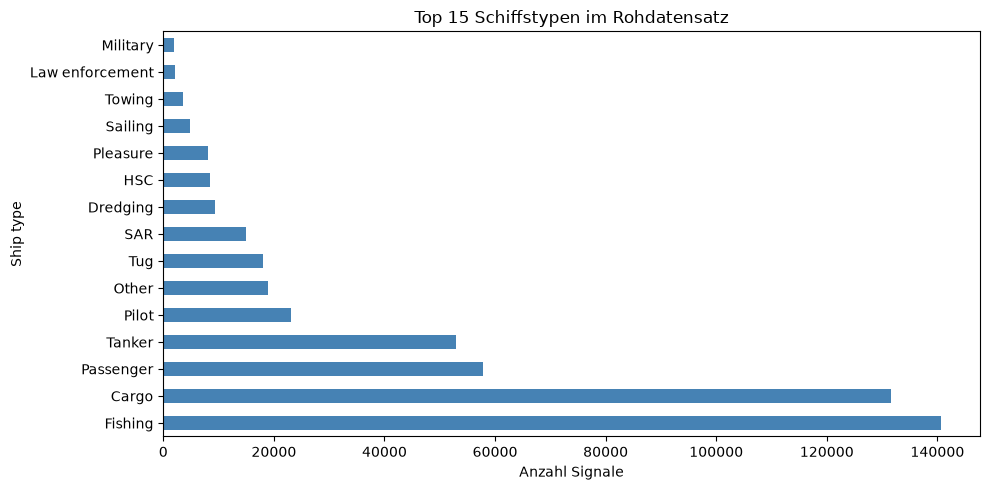

In [6]:
# Verteilung der Schiffstypen
print('=== Schiffstypen ===')
print(df['Ship type'].value_counts().head(15))

fig, ax = plt.subplots(figsize=(10, 5))
df['Ship type'].value_counts().head(15).plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Anzahl Signale')
ax.set_title('Top 15 Schiffstypen im Rohdatensatz')
plt.tight_layout()
plt.show()

**Beobachtungen:**

- 500.000 Signale, 1.808 Schiffe
- Viele fehlende Werte bei Cargo type (83.6%) und ETA (34%)
- Latitude 91.0 = AIS-Default wenn kein GPS — muss rausgefiltert werden
- Viele Schiffe stehen still (SOG=0) — die behalten wir aber, weil Größe/Tiefgang trotzdem typisch sind
- Zeitfenster ist nur ca. 1 Stunde (01.01.2026)

4 — Train/Test Split

Gibt es hier nicht — Unsupervised Learning hat keine Trainingsphase.

5 — Cleaning und Preprocessing

**Filterregeln:**
- Latitude: nur 50°–60° Nord (Nordsee + westliche Ostsee)
- Longitude: nur -5° bis 21° Ost
- Schiffe mit SOG=0 bleiben drin — auch ankernde/liegende Schiffe zeigen typisches Verhalten (Größe, Tiefgang etc.)

In [7]:
# Filtern auf gültige Positionen (Nordsee + westliche Ostsee)
valid_mask = (
    (df['Latitude'] >= 50) & (df['Latitude'] <= 60) &
    (df['Longitude'] >= -5) & (df['Longitude'] <= 21)
)
df = df[valid_mask].copy()
print(f'Nach Filterung: {len(df)} Zeilen ({valid_mask.mean():.1%} der Originaldaten)')
print(f'Verbleibende Schiffe: {df["MMSI"].nunique()}')

Nach Filterung: 498717 Zeilen (99.7% der Originaldaten)
Verbleibende Schiffe: 1794


In [8]:
# Schiffstypen zu Hauptkategorien zusammenfassen
type_map = {}
for val in df['Ship type'].dropna().unique():
    val_str = str(val).lower()
    if 'cargo' in val_str:
        type_map[val] = 'Cargo'
    elif 'tanker' in val_str:
        type_map[val] = 'Tanker'
    elif 'fishing' in val_str:
        type_map[val] = 'Fishing'
    elif 'passenger' in val_str:
        type_map[val] = 'Passenger'
    elif 'sailing' in val_str or 'pleasure' in val_str:
        type_map[val] = 'Sailing/Pleasure'
    elif 'tug' in val_str or 'towing' in val_str:
        type_map[val] = 'Tug/Towing'

df['ShipCategory'] = df['Ship type'].map(type_map)
df = df.dropna(subset=['ShipCategory'])
print(f'Nach Typ-Mapping: {len(df)} Zeilen, {df["MMSI"].nunique()} Schiffe')
print(df['ShipCategory'].value_counts())

Nach Typ-Mapping: 416993 Zeilen, 1411 Schiffe
ShipCategory
Fishing             140616
Cargo               131503
Passenger            57708
Tanker               52990
Tug/Towing           21609
Sailing/Pleasure     12567
Name: count, dtype: int64


**Anmerkung zum Typ-Filtering:** Wir nutzen den gemeldeten Typ hier nur um den Scope
auf die sechs kommerziellen Hauptkategorien einzugrenzen. Typen wie Military oder SAR
zeigen sehr spezielles Verhalten und würden die Cluster verzerren. Die eigentliche
Validierung passiert danach rein über das Fahrverhalten.

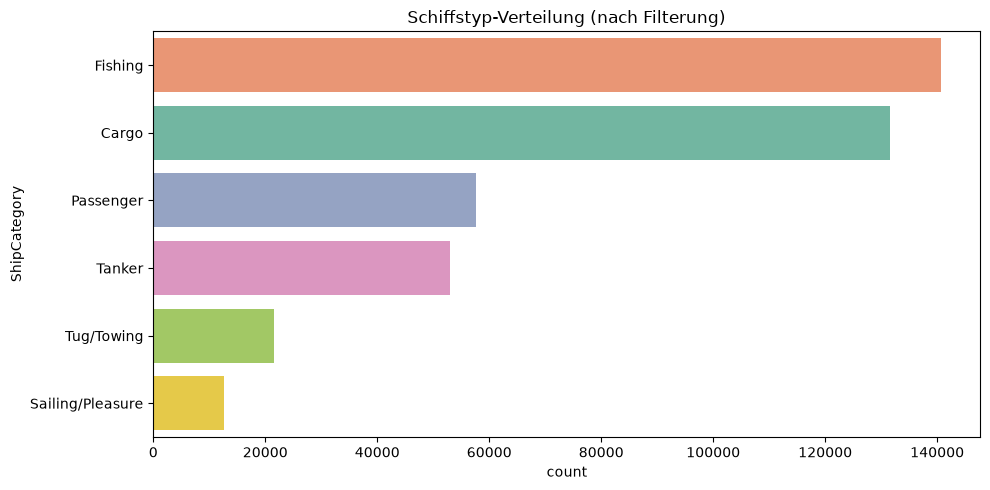

In [9]:
# Verteilung nach Filterung und Typ-Mapping
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df, y='ShipCategory', order=df['ShipCategory'].value_counts().index, ax=ax,
              hue=df['ShipCategory'], palette='Set2', legend=False)
ax.set_title('Schiffstyp-Verteilung (nach Filterung)')
plt.tight_layout()
plt.show()

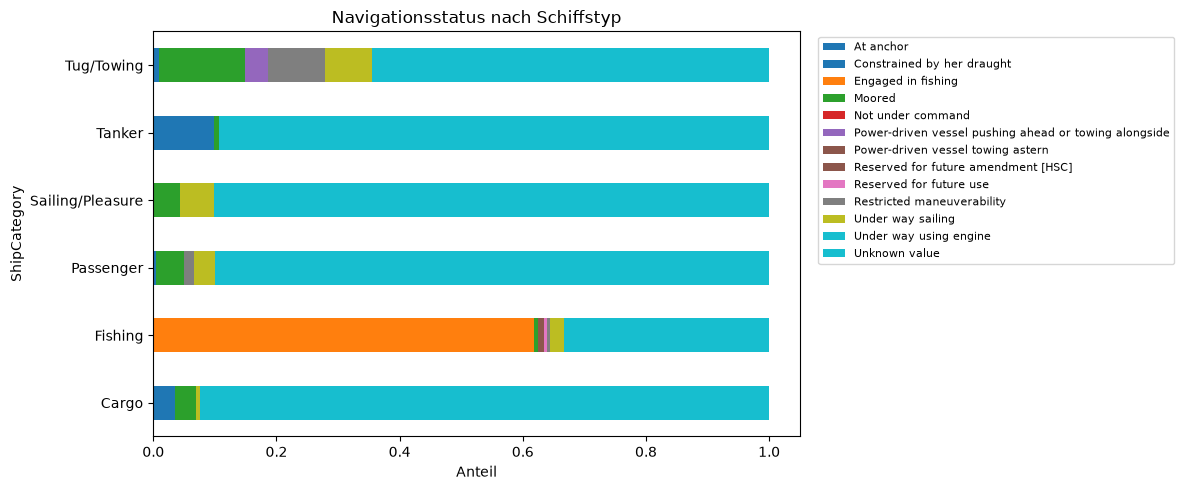

In [10]:
# Navigationsstatus nach Schiffstyp (gestapeltes Balkendiagramm)
cross_nav = pd.crosstab(df['ShipCategory'], df['Navigational status'], normalize='index')
cross_nav.plot(kind='barh', stacked=True, figsize=(12, 5), colormap='tab10')
plt.title('Navigationsstatus nach Schiffstyp')
plt.xlabel('Anteil')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

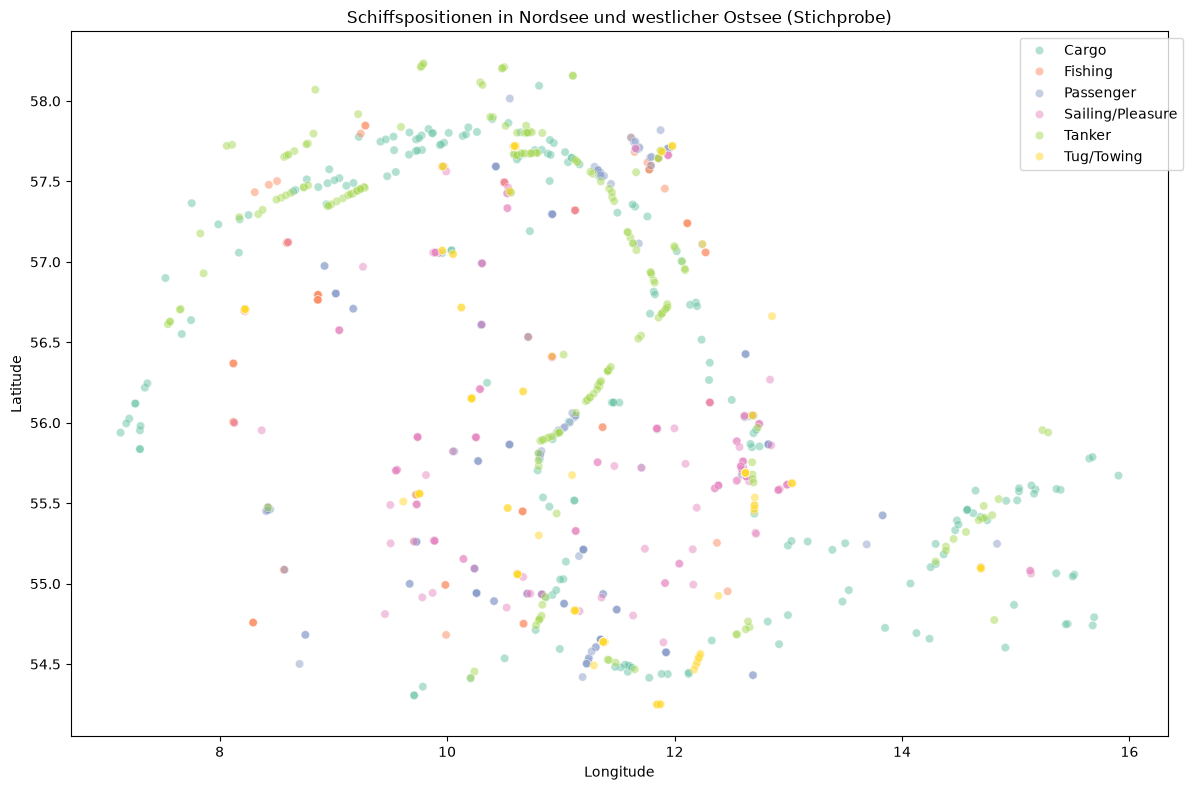

In [11]:
# Geografische Verteilung der Schiffe
sample = df.groupby('ShipCategory').apply(
    lambda x: x.sample(min(200, len(x)), random_state=42), include_groups=False
).reset_index(level=0)

fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(data=sample, x='Longitude', y='Latitude', hue='ShipCategory',
                alpha=0.5, ax=ax, palette='Set2')
ax.set_title('Schiffspositionen in Nordsee und westlicher Ostsee (Stichprobe)')
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Erkenntnisse aus der explorativen Datenanalyse:**

1. Der Datensatz enthält 500.000 AIS-Signale von 1.808 Schiffen. Nach geografischer Filterung (Nordsee) und Typ-Mapping auf sechs Kategorien bleiben 1.794 Schiffe.
2. Cargo type fehlt bei 83,6% der Schiffe und ist damit als Feature unbrauchbar.
3. Die Navigationsstatusverteilung unterscheidet sich deutlich nach Schiffstyp — Fishing-Schiffe nutzen den Status 7 (Fishing) häufig, Cargo und Tanker fast nie.
4. Geografisch verteilen sich die Schiffstypen unterschiedlich: Fischer konzentrieren sich küstennah, Cargo und Tanker nutzen eher Schifffahrtsrouten.
5. Ungültige GPS-Werte (Latitude=91.0) und Ausreißer in den Koordinaten erfordern sorgfältiges Cleaning.

6 — Feature Engineering und Feature Selection

Zusätzlich nutzen wir externe Daten — hier Hafenkoordinaten.

**16 Features:**

| Kategorie | Features | Quelle |
|-----------|----------|--------|
| Physisch (3) | Length, Width, Draught | AIS |
| Geschwindigkeit (5) | SOG_mean, SOG_max, SOG_std, SOG_range, SOG_median | AIS |
| Kurs (1) | COG_std | AIS |
| Navigation (2) | NavStatus_Fishing, NavStatus_Underway | AIS |
| Geografisch (3) | Lat_mean, Lon_mean, Geo_spread | AIS |
| Extern (2) | Dist_nearest_port_km, Nearest_port_type | nordseehaefen.csv |

In [12]:
# Externe Daten: Nordseehäfen (Quelle: OpenStreetMap / Wikipedia)
df_haefen = pd.read_csv('nordseehaefen.csv')
print(f'Häfen geladen: {len(df_haefen)}')
print(df_haefen[['Hafen', 'Latitude', 'Longitude', 'Typ']])

# Haversine-Distanzfunktion (Entfernung in km)
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    la1, lo1, la2, lo2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = la2 - la1
    dlon = lo2 - lo1
    a = np.sin(dlat/2)**2 + np.cos(la1)*np.cos(la2)*np.sin(dlon/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

Häfen geladen: 10
           Hafen  Latitude  Longitude        Typ
0        Hamburg   53.5461     9.9660  Großhafen
1    Bremerhaven   53.5396     8.5809  Großhafen
2      Rotterdam   51.9054     4.4661  Großhafen
3      Antwerpen   51.2996     4.3364  Großhafen
4      Amsterdam   52.4075     4.8978  Großhafen
5        Esbjerg   55.4760     8.4519  Großhafen
6     Gothenburg   57.7089    11.9746  Großhafen
7  Wilhelmshaven   53.5109     8.1265  Großhafen
8       Cuxhaven   53.8697     8.7072  Großhafen
9    Brunsbüttel   53.8950     9.1382  Großhafen


In [13]:
# Aggregation pro Schiff (MMSI) – jedes Schiff wird ein Datenpunkt
# Jedes Schiff sendet viele AIS-Signale pro Stunde. Wir fassen alle Signale
# eines Schiffes (gleiche MMSI) zu einem einzigen Datenpunkt zusammen.
# Für jedes Feature wird eine sinnvolle Statistik gewählt: Mittelwert, Median,
# Standardabweichung (für Variabilität) oder Anteil (für binäre Variablen).

# Positionen validieren (unrealistische Koordinaten → NaN)
df['Lat_valid'] = df['Latitude'].where((df['Latitude'] > 20) & (df['Latitude'] < 75), np.nan)
df['Lon_valid'] = df['Longitude'].where((df['Longitude'] > -10) & (df['Longitude'] < 30), np.nan)

# Navigationsstatus binär kodieren (für spätere Anteilsberechnung pro Schiff)
df['is_fishing'] = (df['Navigational status'] == 'Engaged in fishing').astype(int)
df['is_moored'] = (df['Navigational status'] == 'Moored').astype(int)
df['is_underway'] = (df['Navigational status'] == 'Under way using engine').astype(int)

# Aggregation: eine Zeile pro Schiff mit Verhaltens-Features
agg = df.groupby('MMSI').agg(
    ShipCategory=('ShipCategory', 'first'),  # Nur für spätere Validierung, KEIN Training-Feature!
    # Physische Merkmale (A+B=Länge, C+D=Breite lt. AIS-Spezifikation)
    Length=('A', lambda x: x.dropna().median() + df.loc[x.index, 'B'].dropna().median() if x.dropna().median() == x.dropna().median() else 0),
    Width=('C', lambda x: x.dropna().median() + df.loc[x.index, 'D'].dropna().median() if x.dropna().median() == x.dropna().median() else 0),
    Draught=('Draught', 'median'),
    # Geschwindigkeits-Features (mean, max, std, range, median → 5 Perspektiven)
    SOG_mean=('SOG', 'mean'),
    SOG_max=('SOG', 'max'),
    SOG_std=('SOG', 'std'),        # Variabilität der Geschwindigkeit
    SOG_range=('SOG', lambda x: x.max() - x.min()),  # Spanne: max - min
    SOG_median=('SOG', 'median'),
    # Kurs-Feature: Standardabweichung des Course Over Ground
    COG_std=('COG', lambda x: x.dropna().std()),  # Hoher Wert = häufige Kursänderungen
    # Navigationsstatus: Anteil der Signale im jeweiligen Status
    NavStatus_Fishing=('is_fishing', 'mean'),    # 0.0–1.0, Anteil "Engaged in fishing"
    NavStatus_Underway=('is_underway', 'mean'),  # 0.0–1.0, Anteil "Under way"
    # Geografische Features
    Lat_mean=('Lat_valid', 'mean'),
    Lon_mean=('Lon_valid', 'mean'),
    # Geo_spread: Euklidische Norm der Standardabweichungen → Bewegungsradius
    Geo_spread=('Lat_valid', lambda x: np.sqrt(x.std()**2 + df.loc[x.index, 'Lon_valid'].std()**2) if len(x) > 1 else 0),
).reset_index()

# NaN/Inf durch 0 ersetzen (z.B. Schiffe mit nur einem Signal → std = NaN)
agg = agg.fillna(0)
agg = agg.replace([np.inf, -np.inf], 0)

# Hafendistanz berechnen (Haversine-Formel für sphärische Distanz)
for i, row in agg.iterrows():
    dists = [haversine(row['Lat_mean'], row['Lon_mean'], h['Latitude'], h['Longitude'])
             for _, h in df_haefen.iterrows()]
    agg.loc[i, 'Dist_nearest_port_km'] = min(dists)
    nearest_idx = np.argmin(dists)
    agg.loc[i, 'Nearest_port_type'] = 1  # Alle Häfen in unserer CSV sind 'Großhafen' → immer 1

# Nur Schiffe mit genug Signalen behalten (mind. 5 → stabile Statistiken)
min_signals = 5
signal_counts = df.groupby('MMSI').size()
valid_mmsi = signal_counts[signal_counts >= min_signals].index
agg = agg[agg['MMSI'].isin(valid_mmsi)].reset_index(drop=True)

print(f'Aggregierte Schiffe: {len(agg)}')
print(f'Verteilung nach Kategorie:')
print(agg['ShipCategory'].value_counts())

Aggregierte Schiffe: 1394
Verteilung nach Kategorie:
ShipCategory
Fishing             382
Cargo               327
Sailing/Pleasure    295
Passenger           175
Tanker              117
Tug/Towing           98
Name: count, dtype: int64


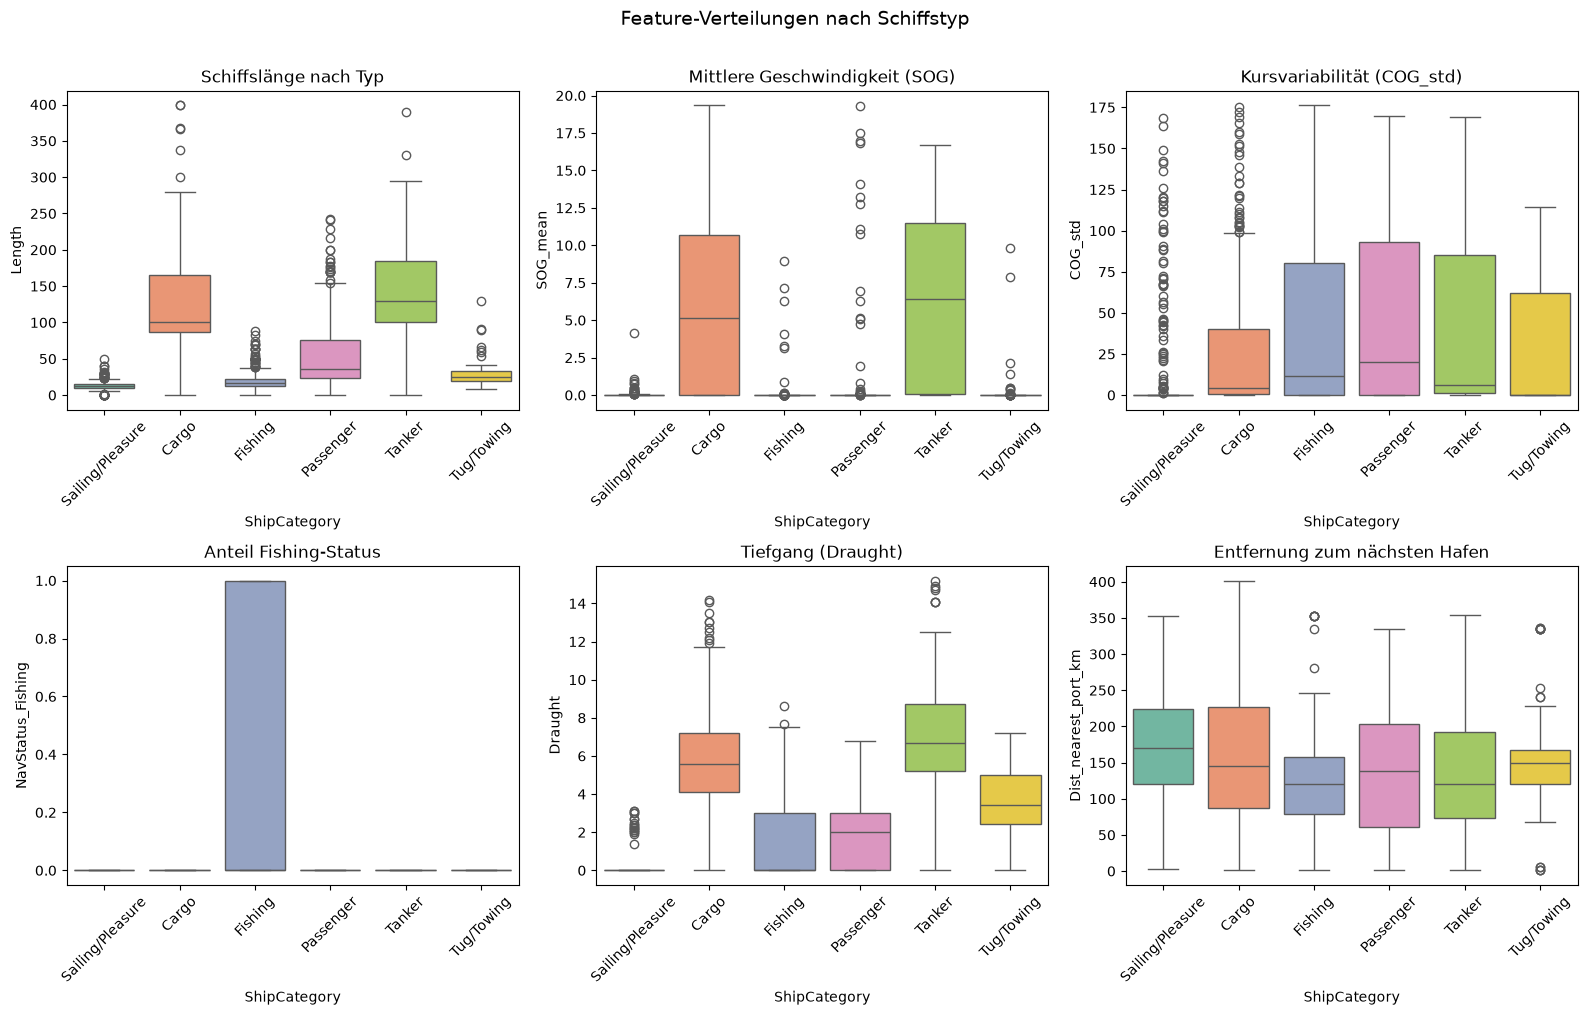

In [14]:
# Verteilungen zentraler Features nach Schiffstyp (Boxplots)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

sns.boxplot(data=agg, x='ShipCategory', y='Length', ax=axes[0,0], hue='ShipCategory', palette='Set2', legend=False)
axes[0,0].set_title('Schiffslänge nach Typ')
axes[0,0].tick_params(axis='x', rotation=45)

sns.boxplot(data=agg, x='ShipCategory', y='SOG_mean', ax=axes[0,1], hue='ShipCategory', palette='Set2', legend=False)
axes[0,1].set_title('Mittlere Geschwindigkeit (SOG)')
axes[0,1].tick_params(axis='x', rotation=45)

sns.boxplot(data=agg, x='ShipCategory', y='COG_std', ax=axes[0,2], hue='ShipCategory', palette='Set2', legend=False)
axes[0,2].set_title('Kursvariabilität (COG_std)')
axes[0,2].tick_params(axis='x', rotation=45)

sns.boxplot(data=agg, x='ShipCategory', y='NavStatus_Fishing', ax=axes[1,0], hue='ShipCategory', palette='Set2', legend=False)
axes[1,0].set_title('Anteil Fishing-Status')
axes[1,0].tick_params(axis='x', rotation=45)

sns.boxplot(data=agg, x='ShipCategory', y='Draught', ax=axes[1,1], hue='ShipCategory', palette='Set2', legend=False)
axes[1,1].set_title('Tiefgang (Draught)')
axes[1,1].tick_params(axis='x', rotation=45)

sns.boxplot(data=agg, x='ShipCategory', y='Dist_nearest_port_km', ax=axes[1,2], hue='ShipCategory', palette='Set2', legend=False)
axes[1,2].set_title('Entfernung zum nächsten Hafen')
axes[1,2].tick_params(axis='x', rotation=45)

plt.suptitle('Feature-Verteilungen nach Schiffstyp', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [15]:
# Feature-Sets: einmal mit, einmal ohne externe Hafendaten
features_ohne_hafen = [
    'Length', 'Width', 'Draught',
    'SOG_mean', 'SOG_max', 'SOG_std', 'SOG_range', 'SOG_median',
    'COG_std',
    'NavStatus_Fishing', 'NavStatus_Underway',
    'Lat_mean', 'Lon_mean', 'Geo_spread',
]

features_mit_hafen = features_ohne_hafen + ['Dist_nearest_port_km', 'Nearest_port_type']

# Wir arbeiten zunächst mit dem erweiterten Set (16 Features)
features = features_mit_hafen

# StandardScaler (Mittelwert 0, Varianz 1) – wichtig für distanzbasierte Verfahren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(agg[features].values)

print(f'Feature-Matrix: {X_scaled.shape}')
print(f'{len(features)} Features ausgewählt')

Feature-Matrix: (1394, 16)
16 Features ausgewählt


In [16]:
# Varianz-Check: Hat Nearest_port_type überhaupt Unterschiede?
print(f'Nearest_port_type — Unique Werte: {agg["Nearest_port_type"].nunique()}')
print(f'Verteilung:\n{agg["Nearest_port_type"].value_counts()}')
print()
print('=> Nur ein Wert! Nearest_port_type bringt keine Varianz und damit keine Information.')
print('   Wir behalten es trotzdem, um den Ansatz der Datenanreicherung zu dokumentieren.')

Nearest_port_type — Unique Werte: 1
Verteilung:
Nearest_port_type
1.0    1394
Name: count, dtype: int64

=> Nur ein Wert! Nearest_port_type bringt keine Varianz und damit keine Information.
   Wir behalten es trotzdem, um den Ansatz der Datenanreicherung zu dokumentieren.


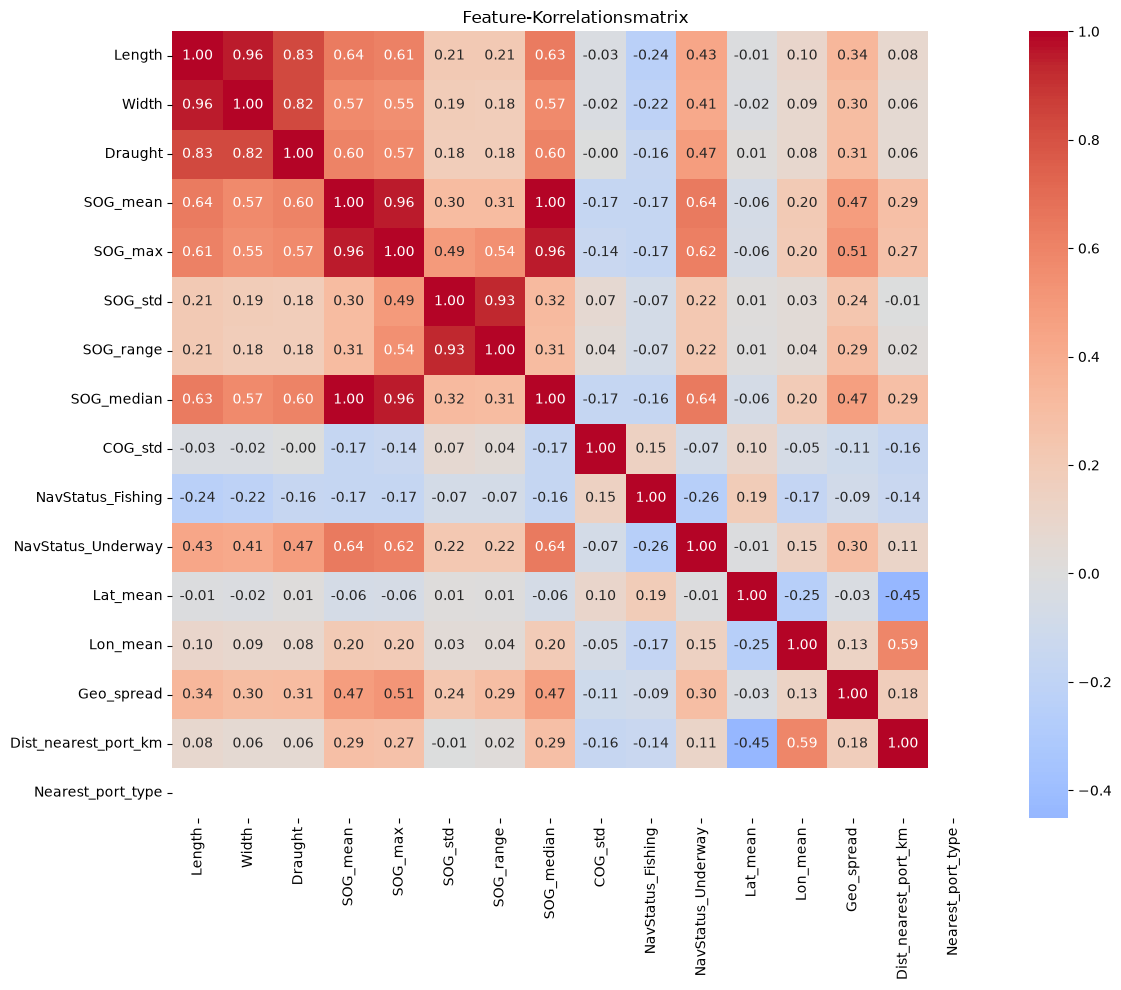

In [17]:
# Korrelationsmatrix
corr = agg[features].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            xticklabels=features, yticklabels=features, ax=ax)
ax.set_title('Feature-Korrelationsmatrix')
plt.tight_layout()
plt.show()

**Zur Multikollinearität:** SOG_mean und SOG_median korrelieren mit 1,00 (gerundet). Normalerweise
würde man einen davon droppen. Hier behalte ich beide, weil: (1) K-Means und DBSCAN arbeiten auf
skalierten Daten, die Redundanz verzerrt die Distanzen nur minimal; (2) der Isolation Forest splittet
auf einzelnen Features und profitiert davon, verschiedene SOG-Varianten zur Auswahl zu haben;
(3) das Droppen würde den Feature-Vektor von 16 auf 15 reduzieren, bringt aber keinen klaren Vorteil.

Nearest_port_type hat (wie oben gesehen) nur einen einzigen Wert — es bringt also keine Varianz.
In einer saubereren Version hätte ich es vor dem Training entfernt. Ich behalte es hier, um den
Ansatz mit externen Daten vollständig zu dokumentieren.

In [18]:
# PCA für 2D-Visualisierung
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f'Erklärte Varianz: PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%}')
print(f'Gesamt: {sum(pca.explained_variance_ratio_):.1%}')
# Hinweis: 52% erklärte Varianz ist normal bei 16 Features. PCA dient hier nur
# der Visualisierung — das Clustering selbst nutzt alle 16 Features.

Erklärte Varianz: PC1=38.8%, PC2=13.2%
Gesamt: 52.0%


**Erkenntnisse aus dem Feature Engineering:**

- Nach der Aggregation auf Schiffsebene (min. 5 Signale) verbleiben 1.394 Schiffe mit 16 Features.
- Die Korrelationsmatrix zeigt starke Multikollinearität bei den SOG-Features (SOG_mean vs. SOG_median: 1,00). Ich behalte beide trotzdem, weil K-Means und DBSCAN mit StandardScaler arbeiten und der Isolation Forest ohnehin auf einzelnen Features splittet. Ein Droppen würde hier keinen klaren Vorteil bringen, aber Information verlieren.
- Die PCA-Projektion (52% Varianz erklärt) zeigt bereits visuell erkennbare Gruppierungen, was für den Einsatz von Clustering-Methoden spricht.
- Die externen Hafendaten (Dist_nearest_port_km, Nearest_port_type) sind integriert, aber Nearest_port_type hat nur einen einzigen Wert im Datensatz — das wird im Modellvergleich noch relevant.

7 — Modellierung und Hyperparameter-Tuning

**7a) K-Means Clustering**

K-Means teilt die Daten in k Cluster auf, wobei jeder Punkt zum nächsten Zentroid gehört.
Vorteil: einfach, gut interpretierbar, Elbow + Silhouette als Metriken.
Nachteil: man muss k vorgeben und es nimmt kugelförmige Cluster an.

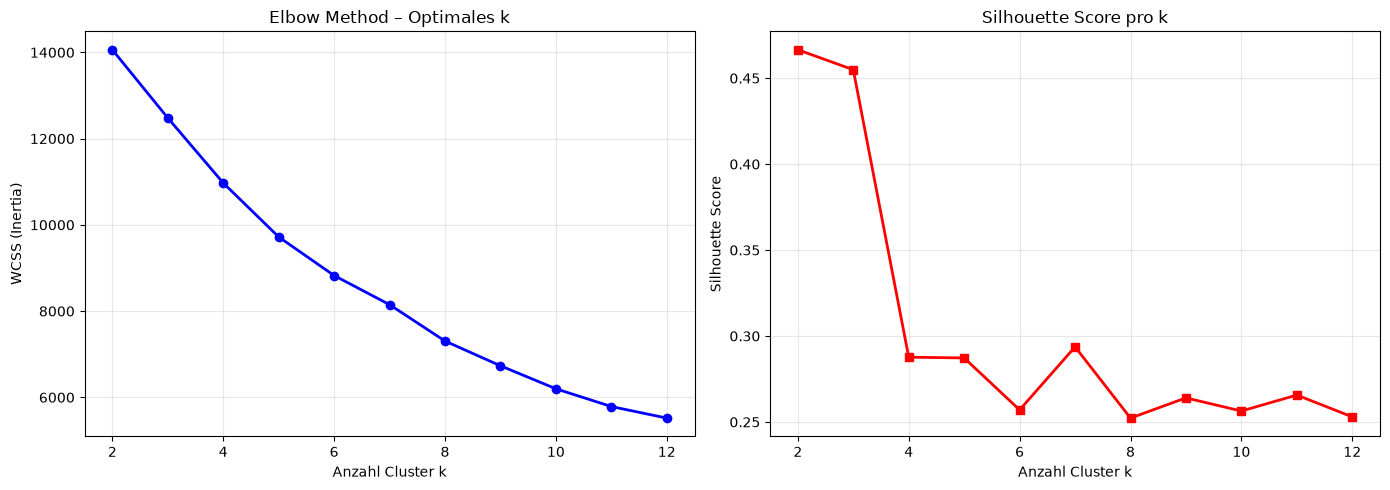

Silhouette Scores:
  k=2: 0.4665 <-- best
  k=3: 0.4549
  k=4: 0.2877
  k=5: 0.2872
  k=6: 0.2570
  k=7: 0.2937
  k=8: 0.2523
  k=9: 0.2640
  k=10: 0.2563
  k=11: 0.2657
  k=12: 0.2529


In [19]:
# Optimale Clusteranzahl bestimmen (Elbow Method + Silhouette)
# Teste k=2 bis k=12 (11 Runden)
K_range = range(2, 13)
wcss = []
sil_scores = []

for k in K_range:
    km_test = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=30, max_iter=300)
    labels = km_test.fit_predict(X_scaled)
    wcss.append(km_test.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(K_range, wcss, 'bo-', linewidth=2)
ax1.set_xlabel('Anzahl Cluster k')
ax1.set_ylabel('WCSS (Inertia)')
ax1.set_title('Elbow Method – Optimales k')
ax1.grid(True, alpha=0.3)

ax2.plot(K_range, sil_scores, 'rs-', linewidth=2)
ax2.set_xlabel('Anzahl Cluster k')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Score pro k')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Silhouette Scores:')
for k, s in zip(K_range, sil_scores):
    marker = ' <-- best' if s == max(sil_scores) else ''
    print(f'  k={k}: {s:.4f}{marker}')

In [20]:
# K-Means fitten: k=6 gewählt
# Begründung: Wir haben 6 Schiffskategorien im Datensatz (Cargo, Tanker, Fishing,
# Passenger, Sailing/Pleasure, Tug/Towing). Wenn die Cluster den realen Typen
# entsprechen, sollte k≈6 am besten interpretierbar sein.
# Der Silhouette Score ist bei k=2 zwar am höchsten, aber k=2 würde die Schiffstypen
# zu stark zusammenfassen und die Fragestellung nicht beantworten.

chosen_k = 6
km = KMeans(n_clusters=chosen_k, init='k-means++', random_state=42, n_init=30, max_iter=300)
agg['KM_Cluster'] = km.fit_predict(X_scaled)

sil_km = silhouette_score(X_scaled, agg['KM_Cluster'])
print(f'K-Means (k={chosen_k}) Silhouette Score: {sil_km:.4f}')
print(f'Zum Vergleich: k=3 hätte Silhouette {max(sil_scores):.4f}')
print(f'\nCluster-Größen:')
print(agg['KM_Cluster'].value_counts().sort_index())

K-Means (k=6) Silhouette Score: 0.2570
Zum Vergleich: k=3 hätte Silhouette 0.4665

Cluster-Größen:
KM_Cluster
0    345
1    230
2    138
3    179
4     16
5    486
Name: count, dtype: int64


In [21]:
# Cluster-Statistiken
for c in sorted(agg['KM_Cluster'].unique()):
    sub = agg[agg['KM_Cluster'] == c]
    types = sub['ShipCategory'].value_counts().to_dict()
    dominant = max(types, key=types.get)
    print(f'Cluster {c} (n={len(sub)}): Dominant = {dominant}')
    print(f'  Länge: {sub["Length"].mean():.1f}m | Geschw.: {sub["SOG_mean"].mean():.2f} kn')
    print(f'  Breite: {sub["Width"].mean():.1f}m | Kursvar.: {sub["COG_std"].mean():.1f}°')
    print(f'  Tiefgang: {sub["Draught"].mean():.1f}m | Hafendist.: {sub["Dist_nearest_port_km"].mean():.0f} km')
    print(f'  Fishing-Status: {sub["NavStatus_Fishing"].mean():.1%} | Underway: {sub["NavStatus_Underway"].mean():.1%}')
    print(f'  Typen: {types}')
    print()

Cluster 0 (n=345): Dominant = Sailing/Pleasure
  Länge: 24.6m | Geschw.: 0.07 kn
  Breite: 6.3m | Kursvar.: 26.4°
  Tiefgang: 1.2m | Hafendist.: 211 km
  Fishing-Status: 1.2% | Underway: 12.2%
  Typen: {'Sailing/Pleasure': 171, 'Passenger': 57, 'Tug/Towing': 49, 'Cargo': 35, 'Fishing': 30, 'Tanker': 3}

Cluster 1 (n=230): Dominant = Cargo
  Länge: 147.0m | Geschw.: 11.03 kn
  Breite: 22.5m | Kursvar.: 11.4°
  Tiefgang: 7.1m | Hafendist.: 198 km
  Fishing-Status: 0.4% | Underway: 96.9%
  Typen: {'Cargo': 161, 'Tanker': 59, 'Passenger': 7, 'Fishing': 2, 'Tug/Towing': 1}

Cluster 2 (n=138): Dominant = Cargo
  Länge: 151.7m | Geschw.: 0.25 kn
  Breite: 24.5m | Kursvar.: 59.8°
  Tiefgang: 6.6m | Hafendist.: 104 km
  Fishing-Status: 0.0% | Underway: 14.4%
  Typen: {'Cargo': 68, 'Tanker': 43, 'Passenger': 20, 'Fishing': 4, 'Tug/Towing': 3}

Cluster 3 (n=179): Dominant = Fishing
  Länge: 17.8m | Geschw.: 0.10 kn
  Breite: 5.6m | Kursvar.: 47.4°
  Tiefgang: 1.6m | Hafendist.: 108 km
  Fishing-S

**Cluster-Interpretation:**

Man sieht, dass manche Cluster klar von einem Typ dominiert werden (z.B. große Frachter/Tanker
in einem Cluster). Andere sind durchmischter — das ist genau das Interessante. Wenn ein
Cargo-Schiff im "Fischer-Cluster" auftaucht, stimmt da vielleicht was nicht.

Details dazu in der Kreuztabelle weiter unten (Abschnitt 9).

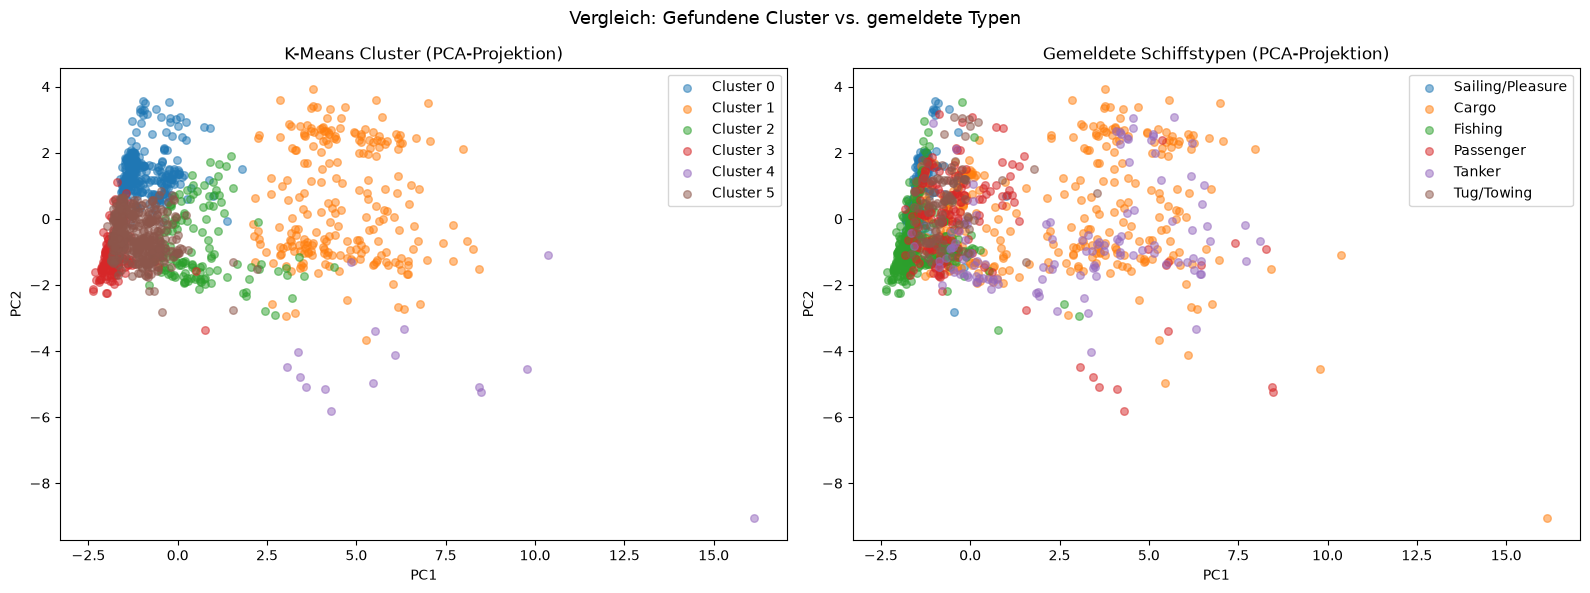

In [22]:
# K-Means Cluster vs. tatsächliche Schiffstypen (PCA)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for c in sorted(agg['KM_Cluster'].unique()):
    mask = agg['KM_Cluster'] == c
    ax1.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Cluster {c}', alpha=0.5, s=30)
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.set_title('K-Means Cluster (PCA-Projektion)')
ax1.legend()

for cat in agg['ShipCategory'].unique():
    mask = agg['ShipCategory'] == cat
    ax2.scatter(X_pca[mask, 0], X_pca[mask, 1], label=cat, alpha=0.5, s=30)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_title('Gemeldete Schiffstypen (PCA-Projektion)')
ax2.legend()

plt.suptitle('Vergleich: Gefundene Cluster vs. gemeldete Typen', fontsize=13)
plt.tight_layout()
plt.show()

In [23]:
# K-Means Anomalie-Erkennung: IQR-Methode (Boxplot-Regel)
distances = km.transform(X_scaled).min(axis=1)

Q1_km = np.percentile(distances, 25)
Q3_km = np.percentile(distances, 75)
IQR_km = Q3_km - Q1_km
threshold_km = Q3_km + 1.5 * IQR_km
agg['KM_Anomaly'] = (distances > threshold_km).astype(int)

print(f'Q1: {Q1_km:.2f}, Q3: {Q3_km:.2f}, IQR: {IQR_km:.2f}')
print(f'Schwellwert (Q3 + 1.5*IQR): {threshold_km:.2f}')
print(f'K-Means Anomalien: {agg["KM_Anomaly"].sum()} ({agg["KM_Anomaly"].mean():.1%})')
print(f'Anomalien nach Schiffstyp:')
print(agg[agg['KM_Anomaly'] == 1]['ShipCategory'].value_counts())

Q1: 1.45, Q3: 2.56, IQR: 1.11
Schwellwert (Q3 + 1.5*IQR): 4.23
K-Means Anomalien: 48 (3.4%)
Anomalien nach Schiffstyp:
ShipCategory
Cargo               18
Tanker              14
Passenger            7
Fishing              6
Sailing/Pleasure     2
Tug/Towing           1
Name: count, dtype: int64


**Zwischenfazit K-Means:** K-Means mit k=6 trennt die Schiffe in interpretierbare Gruppen.
Cluster 3 besteht zu 100% aus Fishing-Schiffen — das Modell hat also rein über Verhaltensdaten
einen realen Schiffstyp erkannt. Die IQR-Methode markiert 48 Schiffe (3,4%) als Anomalien.
Das sind Schiffe, die keinem Cluster richtig zugeordnet werden können.

**7b) DBSCAN**

DBSCAN ist eine dichtebasierte Alternative zu K-Means.
Statt eine feste Clusteranzahl vorzugeben, findet DBSCAN Cluster über die Datendichte.
Punkte die in keinen dichten Bereich fallen werden als Noise markiert — das sind dann
unsere potenziellen Anomalien.

Nachteil: Die Parameter eps und min_samples müssen gut gewählt werden, und bei vielen
Features (wir haben 16) wird es schwierig weil die Daten dünn verteilt sind.

In [24]:
# DBSCAN Hyperparameter-Tuning: Grid Search über 24 Kombinationen
# eps = Radius der Nachbarschaft, min_samples = Mindestanzahl Punkte für Core Point
eps_range = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5]  # Breite Spanne wegen Hochdimensionalität (16 Features)
ms_range = [3, 5, 10, 15]  # Niedrige Werte, da nur 1.394 Schiffe im Datensatz

print(f"{'eps':>6} {'ms':>6} {'Cluster':>8} {'Noise%':>7} {'Silhouette':>11}")
print('-' * 50)

best_sil_db = -1
best_params_db = {}
db_results = []

for eps in eps_range:
    for ms in ms_range:
        db = DBSCAN(eps=eps, min_samples=ms)
        labels = db.fit_predict(X_scaled)
        # Cluster zählen: -1 ist Noise-Label, wird nicht als Cluster gezählt
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = (labels == -1).mean()
        # Filter: Mindestens 2 Cluster und maximal 50% Noise (sonst sinnlos)
        if n_clusters >= 2 and noise_pct < 0.5:
            # Silhouette nur auf Nicht-Noise-Punkte berechnen (Noise hat kein Cluster)
            sil = silhouette_score(X_scaled[labels != -1], labels[labels != -1])
            db_results.append({'eps': eps, 'min_samples': ms, 'n_clusters': n_clusters,
                              'noise_pct': noise_pct, 'silhouette': sil})
            marker = ''
            # Bestes Ergebnis merken (höchster Silhouette Score)
            if sil > best_sil_db:
                best_sil_db = sil
                best_params_db = {'eps': eps, 'min_samples': ms}
                marker = ' <-- best'
            print(f'{eps:6.1f} {ms:6d} {n_clusters:8d} {noise_pct:7.1%} {sil:11.4f}{marker}')
        else:
            reason = '>50% noise' if noise_pct >= 0.5 else f'<2 cluster'
            print(f'{eps:6.1f} {ms:6d} {n_clusters:8d} {noise_pct:7.1%}    ({reason})')

print(f'\nBeste Parameter: eps={best_params_db.get("eps", 2.0)}, min_samples={best_params_db.get("min_samples", 15)}')

   eps     ms  Cluster  Noise%  Silhouette
--------------------------------------------------
   1.0      3       28   17.6%      0.0768 <-- best
   1.0      5       21   24.9%      0.1250 <-- best
   1.0     10       12   40.0%      0.2557 <-- best
   1.0     15        6   52.4%    (>50% noise)
   1.5      3        8    8.5%      0.2388
   1.5      5        7    9.8%      0.2310
   1.5     10        5   13.1%      0.2937 <-- best
   1.5     15        5   16.6%      0.3058 <-- best


   2.0      3        6    5.2%      0.2464


   2.0      5        4    6.1%      0.2744
   2.0     10        4    7.6%      0.2786
   2.0     15        4    8.3%      0.2814
   2.5      3        4    3.3%      0.1219
   2.5      5        2    3.9%      0.1701


   2.5     10        2    4.3%      0.1726
   2.5     15        2    4.7%      0.1763
   3.0      3        3    1.6%      0.3433 <-- best
   3.0      5        1    2.4%    (<2 cluster)
   3.0     10        1    2.9%    (<2 cluster)
   3.0     15        1    3.1%    (<2 cluster)


   3.5      3        1    0.8%    (<2 cluster)
   3.5      5        1    0.9%    (<2 cluster)
   3.5     10        1    1.8%    (<2 cluster)
   3.5     15        1    1.8%    (<2 cluster)

Beste Parameter: eps=3.0, min_samples=3


In [25]:
# DBSCAN mit besten Parametern fitten
if best_params_db:
    db_best = DBSCAN(eps=best_params_db['eps'], min_samples=best_params_db['min_samples'])
else:
    db_best = DBSCAN(eps=2.0, min_samples=15)
agg['DB_Cluster'] = db_best.fit_predict(X_scaled)

n_cl = len(set(agg['DB_Cluster'])) - (1 if -1 in agg['DB_Cluster'].values else 0)
noise_mask = agg['DB_Cluster'] == -1
non_noise = ~noise_mask

if non_noise.sum() > 0 and len(set(agg.loc[non_noise, 'DB_Cluster'])) >= 2:
    sil_db = silhouette_score(X_scaled[non_noise], agg.loc[non_noise, 'DB_Cluster'])
else:
    sil_db = -1

agg['DB_Anomaly'] = noise_mask.astype(int)

print(f'DBSCAN: {n_cl} Cluster, {noise_mask.sum()} Noise-Punkte ({noise_mask.mean():.1%})')
print(f'Silhouette (ohne Noise): {sil_db:.4f}')
print(f'\nAnomalie-Verteilung nach Schiffstyp:')
print(agg[agg['DB_Anomaly'] == 1]['ShipCategory'].value_counts())

DBSCAN: 3 Cluster, 23 Noise-Punkte (1.6%)
Silhouette (ohne Noise): 0.3433

Anomalie-Verteilung nach Schiffstyp:
ShipCategory
Cargo         12
Passenger      4
Tanker         3
Fishing        3
Tug/Towing     1
Name: count, dtype: int64


**Zum DBSCAN-Ergebnis:** Der Noise-Anteil ist mit ca. 1,6% sehr niedrig — das spricht dafür, dass die Daten gut strukturiert sind. DBSCAN ist eigentlich für räumliche 2D/3D-Daten gedacht, funktioniert hier aber überraschend ordentlich. Die Noise-Punkte sind trotzdem interessant als Verdachtsfälle.

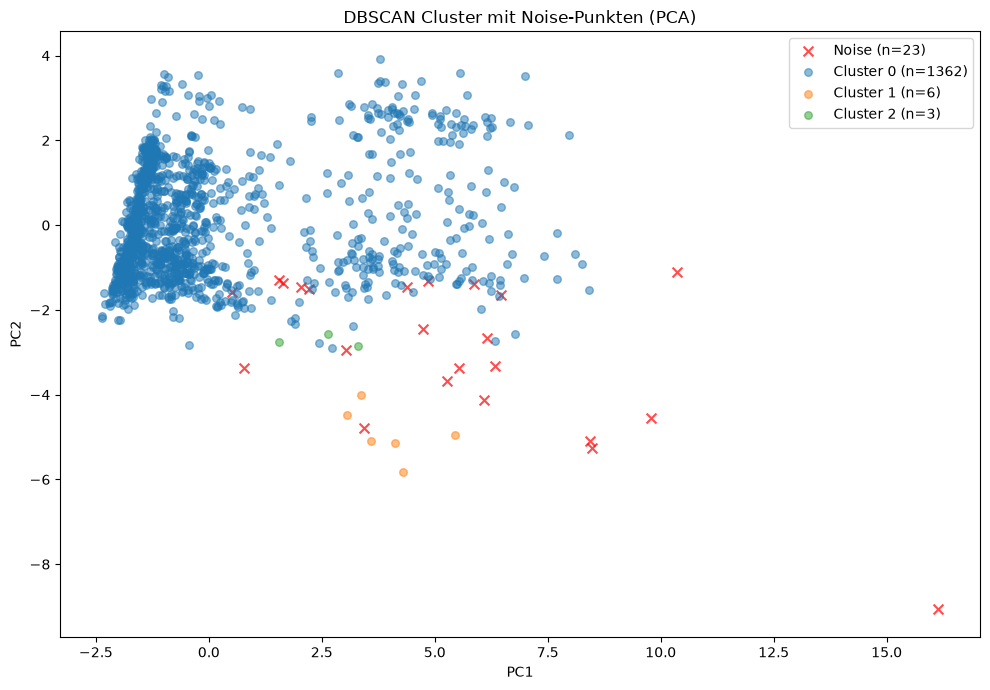

In [26]:
# DBSCAN Ergebnis visualisieren (PCA)
fig, ax = plt.subplots(figsize=(10, 7))
for label in sorted(agg['DB_Cluster'].unique()):
    mask = agg['DB_Cluster'] == label
    if label == -1:
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c='red', marker='x', s=50,
                   label=f'Noise (n={mask.sum()})', alpha=0.7)
    else:
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Cluster {label} (n={mask.sum()})',
                   alpha=0.5, s=30)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('DBSCAN Cluster mit Noise-Punkten (PCA)')
ax.legend()
plt.tight_layout()
plt.show()

**Zwischenfazit DBSCAN:** Mit eps=3,0 und min_samples=3 findet DBSCAN saubere Cluster mit
nur 1,6% Noise. Die 23 Noise-Punkte sind potenzielle Verdachtsfälle, weil kein dichtebasierter
Cluster zu ihnen passt. DBSCAN findet grundsätzlich andere Anomalien als K-Means, weil es
über die lokale Dichte geht statt über globale Zentroide.

**7c) Isolation Forest** (basiert auf Decision Trees)

Isolation Forest macht kein Clustering, sondern erkennt Anomalien direkt. Die Logik:
Ausreißer lassen sich in einem Decision Tree mit weniger Splits isolieren als normale
Datenpunkte.
Bringt eine andere Perspektive rein als die beiden Clustering-Verfahren.

In [27]:
# Isolation Forest Hyperparameter-Tuning (12 Kombinationen)
if_params = [
    {'n_estimators': 100, 'max_features': 1.0, 'contamination': 0.05, 'max_samples': 1.0},
    {'n_estimators': 100, 'max_features': 0.5, 'contamination': 0.05, 'max_samples': 1.0},
    {'n_estimators': 200, 'max_features': 1.0, 'contamination': 0.05, 'max_samples': 1.0},
    {'n_estimators': 200, 'max_features': 0.5, 'contamination': 0.05, 'max_samples': 0.75},
    {'n_estimators': 200, 'max_features': 0.75, 'contamination': 0.05, 'max_samples': 0.5},
    {'n_estimators': 300, 'max_features': 1.0, 'contamination': 0.05, 'max_samples': 1.0},
    {'n_estimators': 300, 'max_features': 0.5, 'contamination': 0.05, 'max_samples': 0.75},
    {'n_estimators': 100, 'max_features': 1.0, 'contamination': 0.03, 'max_samples': 1.0},
    {'n_estimators': 200, 'max_features': 0.5, 'contamination': 0.03, 'max_samples': 0.75},
    {'n_estimators': 200, 'max_features': 1.0, 'contamination': 0.07, 'max_samples': 1.0},
    {'n_estimators': 200, 'max_features': 0.5, 'contamination': 0.07, 'max_samples': 0.75},
    {'n_estimators': 300, 'max_features': 0.75, 'contamination': 0.05, 'max_samples': 0.5},
]

print(f'{"n_est":>6} {"max_f":>6} {"contam":>7} {"max_s":>6} {"Anomalien":>10} {"Mean Score":>11}')
print('-' * 55)

best_if_score = float('inf')
best_if_params = if_params[0]

for p in if_params:
    iso_test = IsolationForest(**p, random_state=42)
    preds = iso_test.fit_predict(X_scaled)
    scores = iso_test.score_samples(X_scaled)
    n_anom = (preds == -1).sum()
    mean_sc = scores.mean()
    marker = ''
    if mean_sc > best_if_score or best_if_score == float('inf'):
        best_if_score = mean_sc
        best_if_params = p
        marker = ' <-- best'
    print(f'{p["n_estimators"]:6d} {p["max_features"]:6.2f} {p["contamination"]:7.2f} '
          f'{p["max_samples"]:6.2f} {n_anom:10d} {mean_sc:11.4f}{marker}')

print(f'\nBeste Parameter: {best_if_params}')

 n_est  max_f  contam  max_s  Anomalien  Mean Score
-------------------------------------------------------


   100   1.00    0.05   1.00         70     -0.4060 <-- best
   100   0.50    0.05   1.00         70     -0.4059 <-- best


   200   1.00    0.05   1.00         70     -0.4063


   200   0.50    0.05   0.75         70     -0.4095


   200   0.75    0.05   0.50         70     -0.4152


...

   300   0.50    0.05   0.75         70     -0.4103
   100   1.00    0.03   1.00         42     -0.4060


   200   0.50    0.03   0.75         42     -0.4095


   200   1.00    0.07   1.00         98     -0.4063


   200   0.50    0.07   0.75         98     -0.4095


   300   0.75    0.05   0.50         70     -0.4166

Beste Parameter: {'n_estimators': 100, 'max_features': 0.5, 'contamination': 0.05, 'max_samples': 1.0}


**Zur Contamination und zum IQR-Schwellwert:** Die Contamination von 5% wird zwar beim Fitting
des Isolation Forests gesetzt (als Startwert für die internen Splits), aber die eigentliche
Anomalie-Erkennung läuft über die IQR-Methode auf den Anomaly-Scores. So ist der Schwellwert
datengetrieben und nicht von einem festen Prozentsatz abhängig. Das Ergebnis (58 Schiffe = 4,2%)
liegt nah an der 5%-Contamination, ist aber nicht identisch — der IQR-Schwellwert passt sich
an die tatsächliche Score-Verteilung an.

In [28]:
# Isolation Forest mit besten Parametern fitten + IQR-Schwellwert
iso = IsolationForest(**best_if_params, random_state=42)
agg['IF_Pred'] = iso.fit_predict(X_scaled)
agg['IF_Score'] = iso.score_samples(X_scaled)

# IQR-Methode auf die Anomaly-Scores (niedrigere Scores = auffaelliger)
Q1_if = np.percentile(agg['IF_Score'], 25)
Q3_if = np.percentile(agg['IF_Score'], 75)
IQR_if = Q3_if - Q1_if
threshold_if = Q1_if - 1.5 * IQR_if
agg['IF_Anomaly'] = (agg['IF_Score'] < threshold_if).astype(int)

print(f'Q1: {Q1_if:.4f}, Q3: {Q3_if:.4f}, IQR: {IQR_if:.4f}')
print(f'Schwellwert (Q1 - 1.5*IQR): {threshold_if:.4f}')
print(f'Isolation Forest Anomalien: {agg["IF_Anomaly"].sum()} von {len(agg)} ({agg["IF_Anomaly"].mean():.1%})')
print(f'Anomalien nach Schiffstyp:')
print(agg[agg['IF_Anomaly'] == 1]['ShipCategory'].value_counts())

Q1: -0.4342, Q3: -0.3639, IQR: 0.0703
Schwellwert (Q1 - 1.5*IQR): -0.5396
Isolation Forest Anomalien: 58 von 1394 (4.2%)
Anomalien nach Schiffstyp:
ShipCategory
Cargo               19
Tanker              14
Passenger           13
Fishing              7
Sailing/Pleasure     4
Tug/Towing           1
Name: count, dtype: int64


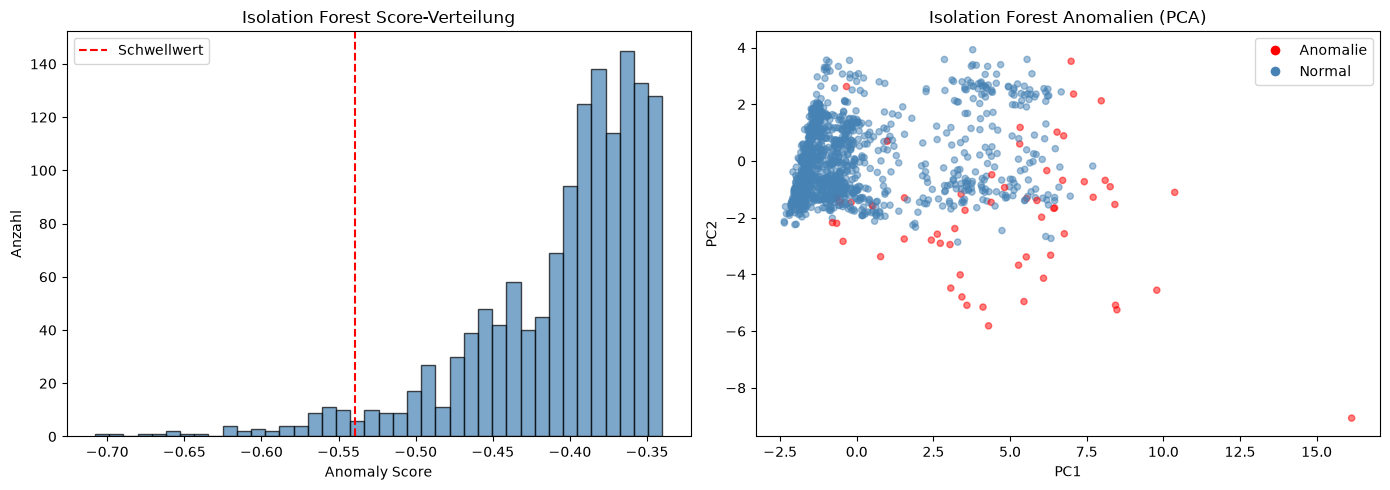

In [29]:
# Isolation Forest: Score-Verteilung und PCA
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(agg['IF_Score'], bins=40, edgecolor='black', alpha=0.7, color='steelblue')
ax1.axvline(x=threshold_if, color='red', linestyle='--',
            label='Schwellwert')
ax1.set_xlabel('Anomaly Score')
ax1.set_ylabel('Anzahl')
ax1.set_title('Isolation Forest Score-Verteilung')
ax1.legend()

colors = ['red' if x == 1 else 'steelblue' for x in agg['IF_Anomaly']]
ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=colors, alpha=0.5, s=20)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_title('Isolation Forest Anomalien (PCA)')
ax2.legend(handles=[
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=8, label='Anomalie'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='steelblue', markersize=8, label='Normal')
])

plt.tight_layout()
plt.show()

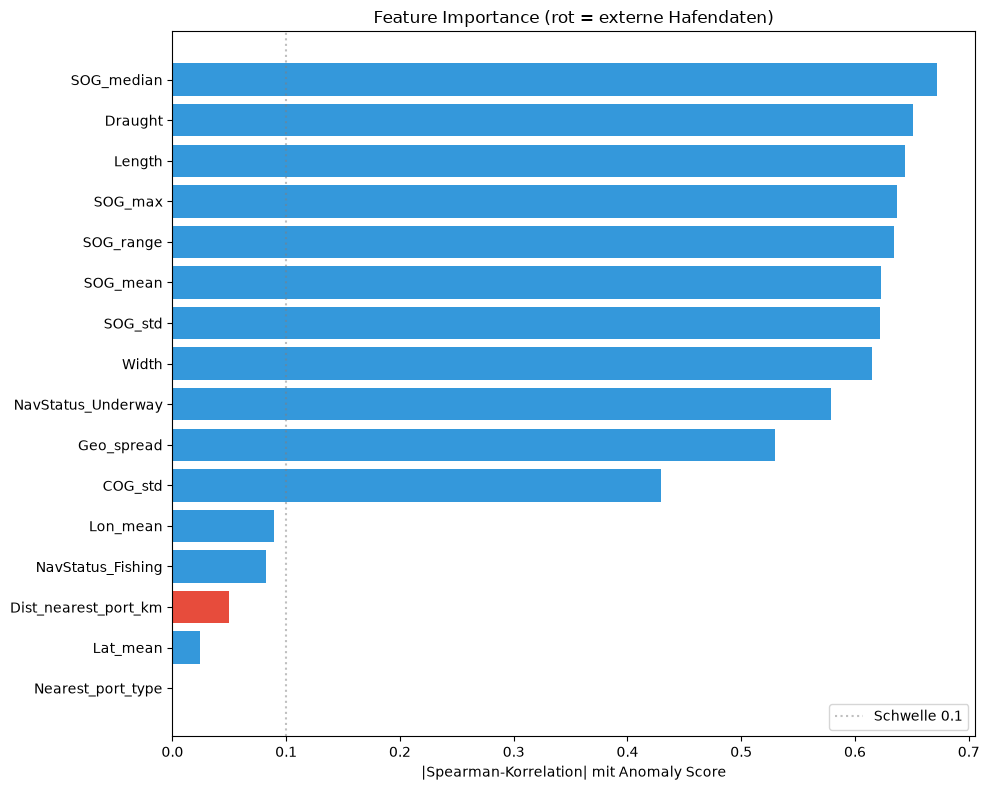

Alle Features nach Wichtigkeit:
  SOG_median               : 0.672
  Draught                  : 0.651
  Length                   : 0.644
  SOG_max                  : 0.637
  SOG_range                : 0.635
  SOG_mean                 : 0.623
  SOG_std                  : 0.622
  Width                    : 0.615
  NavStatus_Underway       : 0.579
  Geo_spread               : 0.530
  COG_std                  : 0.430
  Lon_mean                 : 0.089
  NavStatus_Fishing        : 0.082
  Dist_nearest_port_km     : 0.049 <-- EXTERN
  Lat_mean                 : 0.024
  Nearest_port_type        : 0.000 <-- EXTERN


In [30]:
# Feature Importance: Spearman-Korrelation mit Anomaly Score
importances = []
for j, feat in enumerate(features):
    col = X_scaled[:, j]
    if np.std(col) < 1e-10:
        importances.append(0.0)
    else:
        corr_val, _ = spearmanr(col, agg['IF_Score'].values)
        importances.append(abs(corr_val))

imp_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#e74c3c' if 'port' in f.lower() or 'Nearest' in f else '#3498db' for f in imp_df['Feature']]
ax.barh(imp_df['Feature'], imp_df['Importance'], color=colors)
ax.set_xlabel('|Spearman-Korrelation| mit Anomaly Score')
ax.set_title('Feature Importance (rot = externe Hafendaten)')
ax.axvline(x=0.1, color='gray', linestyle=':', alpha=0.5, label='Schwelle 0.1')
ax.legend()
plt.tight_layout()
plt.show()

print('Alle Features nach Wichtigkeit:')
for _, row in imp_df.sort_values('Importance', ascending=False).iterrows():
    marker = ' <-- EXTERN' if 'port' in row['Feature'].lower() or 'Nearest' in row['Feature'] else ''
    print(f'  {row["Feature"]:<25}: {row["Importance"]:.3f}{marker}')

**Zwischenfazit Isolation Forest:** 58 Schiffe (4,2%) werden als anomal markiert. Die Feature
Importance zeigt, dass SOG_median und Draught die stärksten Treiber sind — der Isolation Forest
erkennt also hauptsächlich Schiffe mit untypischer Geschwindigkeit oder untypischem Tiefgang.
Die Hafendaten landen auf den letzten Plätzen (Rang 14 und 16 von 16).

**Vergleich: mit vs. ohne Hafendaten**

Hier testen wir, ob die externen Daten was bringen.

In [31]:
# Vergleich: 14 Features (ohne Hafen) vs. 16 Features (mit Hafen)
scaler_ohne = StandardScaler()
X_ohne = scaler_ohne.fit_transform(agg[features_ohne_hafen].values)

# K-Means ohne Hafen
km_ohne = KMeans(n_clusters=chosen_k, init='k-means++', random_state=42, n_init=30, max_iter=300)
labels_ohne = km_ohne.fit_predict(X_ohne)
sil_km_ohne = silhouette_score(X_ohne, labels_ohne)

# DBSCAN ohne Hafen
if best_params_db:
    db_ohne = DBSCAN(eps=best_params_db['eps'], min_samples=best_params_db['min_samples'])
else:
    db_ohne = DBSCAN(eps=2.0, min_samples=15)
db_labels_ohne = db_ohne.fit_predict(X_ohne)
noise_ohne = (db_labels_ohne == -1)
non_noise_ohne = ~noise_ohne
if non_noise_ohne.sum() > 0 and len(set(db_labels_ohne[non_noise_ohne])) >= 2:
    sil_db_ohne = silhouette_score(X_ohne[non_noise_ohne], db_labels_ohne[non_noise_ohne])
else:
    sil_db_ohne = -1

# IF ohne Hafen
iso_ohne = IsolationForest(**best_if_params, random_state=42)
if_labels_ohne = iso_ohne.fit_predict(X_ohne)
if_scores_ohne = iso_ohne.score_samples(X_ohne)
Q1_if_ohne = np.percentile(if_scores_ohne, 25)
Q3_if_ohne = np.percentile(if_scores_ohne, 75)
IQR_if_ohne = Q3_if_ohne - Q1_if_ohne
threshold_if_ohne = Q1_if_ohne - 1.5 * IQR_if_ohne
if_anom_ohne = (if_scores_ohne < threshold_if_ohne).sum()

print('=' * 65)
print(f'{"Metrik":<32} {"Ohne Hafen (14)":>15} {"Mit Hafen (16)":>15}')
print('=' * 65)
print(f'{"K-Means Silhouette":<32} {sil_km_ohne:>15.4f} {sil_km:>15.4f}')
print(f'{"DBSCAN Silhouette":<32} {sil_db_ohne:>15.4f} {sil_db:>15.4f}')
print(f'{"DBSCAN Noise-Punkte":<32} {noise_ohne.sum():>15d} {noise_mask.sum():>15d}')
print(f'{"IF Anomalien":<32} {if_anom_ohne:>15d} {agg["IF_Anomaly"].sum():>15d}')
print('=' * 65)
print()
print('Fazit: Die Hafendaten haben nur minimalen Einfluss auf die Ergebnisse.')
print('Das bestätigt die Feature Importance (Rang 15-16 von 16).')
print('Trotzdem behalten wir sie im Modell, um den Ansatz mit externen Daten zu zeigen.')

Metrik                           Ohne Hafen (14)  Mit Hafen (16)
K-Means Silhouette                        0.3112          0.2570
DBSCAN Silhouette                         0.3673          0.3433
DBSCAN Noise-Punkte                           22              23
IF Anomalien                                  59              58

Fazit: Die Hafendaten haben nur minimalen Einfluss auf die Ergebnisse.
Das bestätigt die Feature Importance (Rang 15-16 von 16).
Trotzdem behalten wir sie im Modell, um den Ansatz mit externen Daten zu zeigen.


8 — Evaluation

Metriken für Unsupervised Learning:

- **WCSS / Elbow Method** — Kompaktheit der Cluster, der Knick zeigt das optimale k
- **Silhouette Score** — wie gut passt jeder Punkt zu seinem Cluster vs. dem nächsten Nachbar-Cluster (-1 bis 1, höher = besser)
- **Anomaly Rate** — wie viele Schiffe werden als auffällig markiert (Plausibilitätscheck)

In [32]:
# Ergebnisübersicht aller drei Methoden
print('=' * 60)
print('ERGEBNISÜBERSICHT')
print('=' * 60)
print(f'{"Methode":<25} {"Silhouette":>12} {"Anomalien":>12} {"Rate":>8}')
print('-' * 60)
print(f'{"K-Means (k="+str(chosen_k)+")":<25} {sil_km:>12.4f} {agg["KM_Anomaly"].sum():>12d} {agg["KM_Anomaly"].mean():>8.1%}')
print(f'{"DBSCAN":<25} {sil_db:>12.4f} {agg["DB_Anomaly"].sum():>12d} {agg["DB_Anomaly"].mean():>8.1%}')
print(f'{"Isolation Forest":<25} {"---":>12} {agg["IF_Anomaly"].sum():>12d} {agg["IF_Anomaly"].mean():>8.1%}')
print('=' * 60)

ERGEBNISÜBERSICHT
Methode                     Silhouette    Anomalien     Rate
------------------------------------------------------------
K-Means (k=6)                   0.2570           48     3.4%
DBSCAN                          0.3433           23     1.6%
Isolation Forest                   ---           58     4.2%


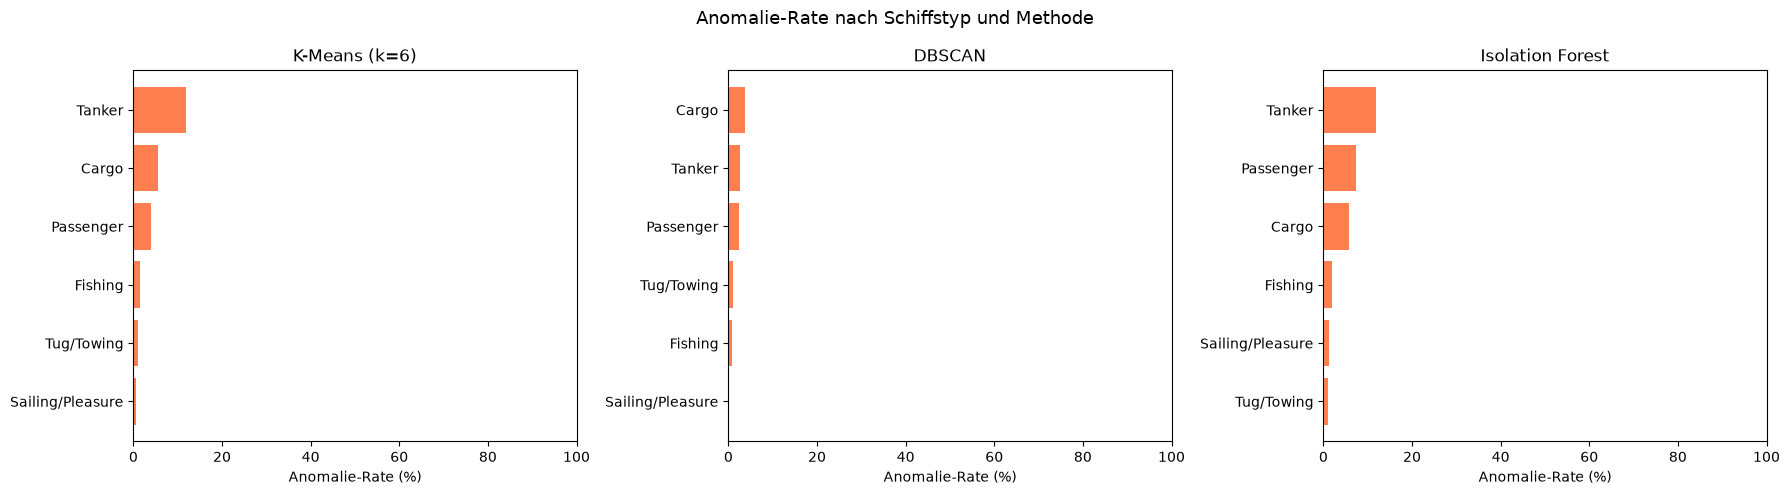

In [33]:
# Anomalie-Rate nach Schiffstyp pro Methode
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (method, col, title) in zip(axes, [
    ('K-Means', 'KM_Anomaly', f'K-Means (k={chosen_k})'),
    ('DBSCAN', 'DB_Anomaly', 'DBSCAN'),
    ('Isolation Forest', 'IF_Anomaly', 'Isolation Forest')
]):
    counts = agg.groupby('ShipCategory')[col].agg(['sum', 'count'])
    counts['rate'] = counts['sum'] / counts['count'] * 100
    counts = counts.sort_values('rate', ascending=True)
    ax.barh(counts.index, counts['rate'], color='coral')
    ax.set_xlabel('Anomalie-Rate (%)')
    ax.set_title(title)
    ax.set_xlim(0, 100)

plt.suptitle('Anomalie-Rate nach Schiffstyp und Methode', fontsize=13)
plt.tight_layout()
plt.show()

**Consensus-Ansatz (eigene Idee)**

Jede Methode hat ihre Schwächen, deshalb kombinieren wir alle drei: Ein Schiff
gilt erst als verdächtig wenn mindestens zwei der drei Methoden anschlagen.
Dadurch fallen zufällige Einzelausreißer raus und die Ergebnisse werden robuster.

In [34]:
# Consensus: Wie viele Methoden markieren jedes Schiff als auffällig?
agg['Anomaly_Sum'] = agg['KM_Anomaly'] + agg['DB_Anomaly'] + agg['IF_Anomaly']

labels_map = {0: 'Unauffällig (0/3)', 1: 'Eine Methode (1/3)',
              2: 'Zwei Methoden (2/3)', 3: 'Alle drei (3/3)'}
print('Consensus-Analyse:')
consensus_counts = agg['Anomaly_Sum'].value_counts().sort_index().rename(labels_map)
print(consensus_counts)

Consensus-Analyse:
Anomaly_Sum
Unauffällig (0/3)      1323
Eine Methode (1/3)       27
Zwei Methoden (2/3)      30
Alle drei (3/3)          14
Name: count, dtype: int64


In [35]:
# Verdächtige Schiffe (>= 2 Methoden markieren als auffällig)
consensus = agg[agg['Anomaly_Sum'] >= 2].sort_values('IF_Score')
if len(consensus) > 0:
    print(f'=== {len(consensus)} verdächtige Schiffe (>= 2 Methoden) ===')
    display_cols = ['MMSI', 'ShipCategory', 'Length', 'Width', 'SOG_mean',
                    'NavStatus_Fishing', 'COG_std', 'Dist_nearest_port_km',
                    'IF_Score', 'Anomaly_Sum']
    print(consensus[display_cols].head(20).to_string(index=False))

=== 44 verdächtige Schiffe (>= 2 Methoden) ===


     MMSI     ShipCategory  Length  Width  SOG_mean  NavStatus_Fishing   COG_std  Dist_nearest_port_km  IF_Score  Anomaly_Sum
255755000            Cargo   114.0   15.0 13.909595                0.0 13.743027            301.957382 -0.707922            3
246843000            Cargo   118.0   16.0  0.612000                0.0  4.071191            231.671335 -0.694140            3
215915000            Cargo   193.0   26.0  0.200971                0.0 29.061195            123.891281 -0.673258            3
636022441            Cargo   366.0   51.0 14.281647                0.0  6.337668             58.784424 -0.664979            3
219835000            Cargo   399.0   58.0  1.586047                0.0 10.047292            106.191118 -0.661659            3
218162000          Fishing    37.0   10.0  8.966212                1.0  3.742028            213.961457 -0.652980            3
265549760        Passenger    40.0    7.0  6.962782                0.0 85.135882             20.327107 -0.643667     

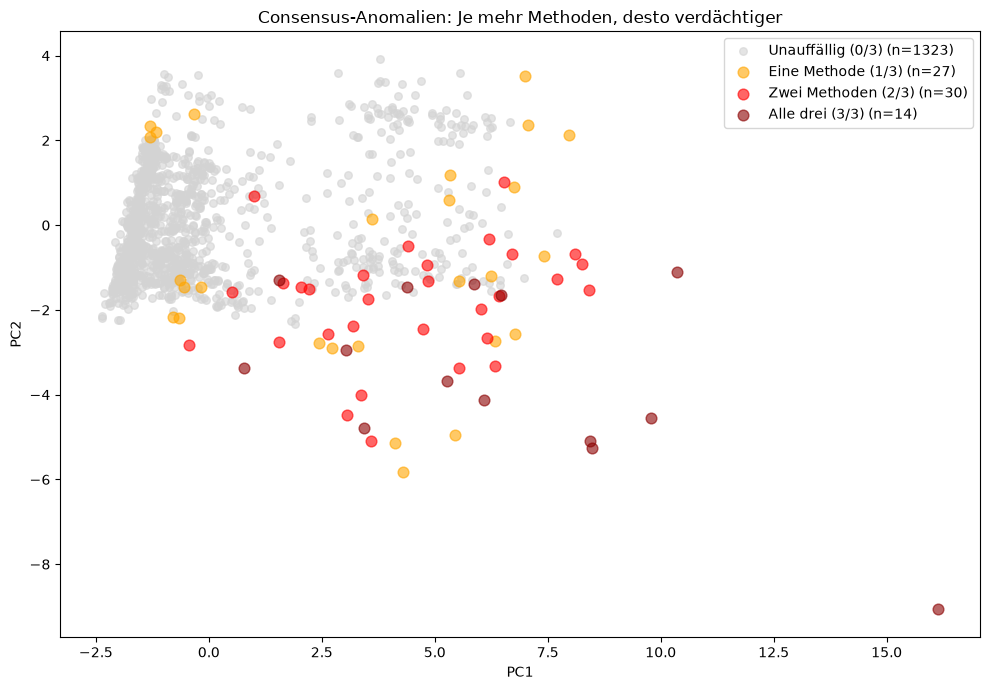

In [36]:
# Consensus-Visualisierung (PCA)
fig, ax = plt.subplots(figsize=(10, 7))
colors = {0: 'lightgray', 1: 'orange', 2: 'red', 3: 'darkred'}
labels_plot = {0: 'Unauffällig (0/3)', 1: 'Eine Methode (1/3)',
               2: 'Zwei Methoden (2/3)', 3: 'Alle drei (3/3)'}
for level in sorted(agg['Anomaly_Sum'].unique()):
    mask = agg['Anomaly_Sum'] == level
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=colors.get(level, 'black'),
               label=f'{labels_plot[level]} (n={mask.sum()})',
               alpha=0.6, s=30 if level == 0 else 60)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Consensus-Anomalien: Je mehr Methoden, desto verdächtiger')
ax.legend()
plt.tight_layout()
plt.show()

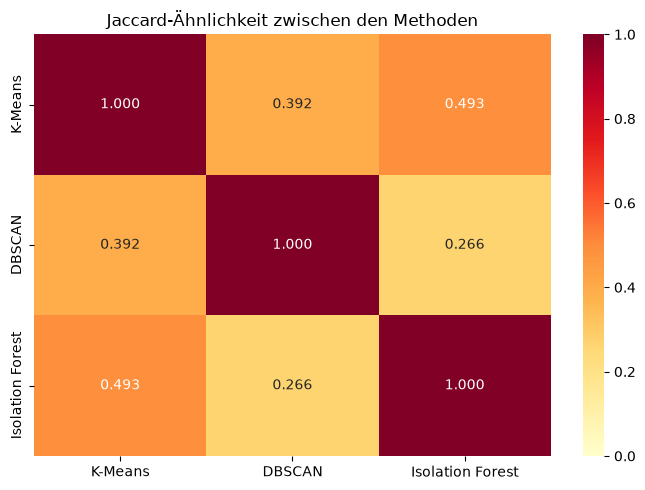

In [37]:
# Übereinstimmung der Methoden: Jaccard-Ähnlichkeit
methods = {'K-Means': agg['KM_Anomaly'], 'DBSCAN': agg['DB_Anomaly'],
           'Isolation Forest': agg['IF_Anomaly']}
jaccard = pd.DataFrame(index=methods.keys(), columns=methods.keys(), dtype=float)

for m1, v1 in methods.items():
    for m2, v2 in methods.items():
        intersection = ((v1 == 1) & (v2 == 1)).sum()
        union = ((v1 == 1) | (v2 == 1)).sum()
        jaccard.loc[m1, m2] = intersection / union if union > 0 else 0.0

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(jaccard.astype(float), annot=True, fmt='.3f', cmap='YlOrRd',
            vmin=0, vmax=1, ax=ax)
ax.set_title('Jaccard-Ähnlichkeit zwischen den Methoden')
plt.tight_layout()
plt.show()

**Sensitivity-Analyse: IQR-Faktor**

Die Boxplot-Regel verwendet den Faktor 1,5 als Konvention. Hier testen wir, wie sich andere
Faktoren auf die Anomalie-Erkennung auswirken. Der Faktor 3,0 steht für "extreme Ausreißer".

In [38]:
# Sensitivity-Analyse: IQR-Faktor 1.5 vs. 2.0 vs. 3.0
print('=== IQR Sensitivity-Analyse ===')
print(f'{"Faktor":<10} {"KM Anomalien":<15} {"IF Anomalien":<15} {"Consensus >=2":<15}')
print('-' * 55)

for factor in [1.5, 2.0, 3.0]:
    # K-Means
    t_km = Q3_km + factor * IQR_km
    km_anom = (distances > t_km).astype(int)
    
    # Isolation Forest
    t_if = Q1_if - factor * IQR_if
    if_anom = (agg['IF_Score'] < t_if).astype(int)
    
    # Consensus (DBSCAN bleibt gleich)
    cons = km_anom + agg['DB_Anomaly'].values + if_anom
    cons_2 = (cons >= 2).sum()
    
    print(f'{factor:<10.1f} {km_anom.sum():<15d} {if_anom.sum():<15d} {cons_2:<15d}')

print()
print('=> Mit steigendem Faktor sinkt die Anzahl der Anomalien.')
print('   Faktor 1,5 ist die Standard-Boxplot-Regel.')
print('   Faktor 3,0 findet nur noch die extremsten Fälle.')

=== IQR Sensitivity-Analyse ===
Faktor     KM Anomalien    IF Anomalien    Consensus >=2  
-------------------------------------------------------
1.5        48              58              44             
2.0        32              26              24             
3.0        10              6               8              

=> Mit steigendem Faktor sinkt die Anzahl der Anomalien.
   Faktor 1,5 ist die Standard-Boxplot-Regel.
   Faktor 3,0 findet nur noch die extremsten Fälle.


9 — Interpretation und Validierung (Pure Unsupervised Ansatz)

Jetzt kommt der entscheidende Schritt: **Die Validierung**. Da der gemeldete Schiffstyp (ShipCategory) bewusst **nicht** als Feature ins Modelltraining eingeflossen ist, können wir ihn jetzt als unabhängige Referenz verwenden, um die Modellergebnisse zu prüfen.

Die Validierung erfolgt auf drei Ebenen:
1. **Kreuztabelle (Cluster vs. gemeldeter Typ):** Wenn ein Cluster fast nur aus einem Schiffstyp besteht, hat das Modell rein über Verhaltensdaten ein reales Muster erkannt. Schiffe, die laut AIS-Meldung z.B. "Cargo" sind, aber im Fishing-Cluster landen, sind Verdachtsfälle.
2. **Anomalie-Aufschlüsselung:** Welche gemeldeten Typen sind unter den Anomalien überrepräsentiert?
3. **Plausibilitätschecks:** Gezielte Prüfung auf widersprüchliches Verhalten (z.B. Cargo-Schiffe mit hohem Fishing-Status, untypisch kleine Frachtschiffe).

Anteil der Schiffstypen pro Cluster (normalisiert):
ShipCategory  Cargo  Fishing  Passenger  Sailing/Pleasure  Tanker  Tug/Towing
KM_Cluster                                                                   
0              0.10     0.09       0.17              0.50    0.01        0.14
1              0.70     0.01       0.03              0.00    0.26        0.00
2              0.49     0.03       0.14              0.00    0.31        0.02
3              0.00     1.00       0.00              0.00    0.00        0.00
4              0.38     0.00       0.50              0.00    0.12        0.00
5              0.12     0.34       0.17              0.26    0.02        0.09


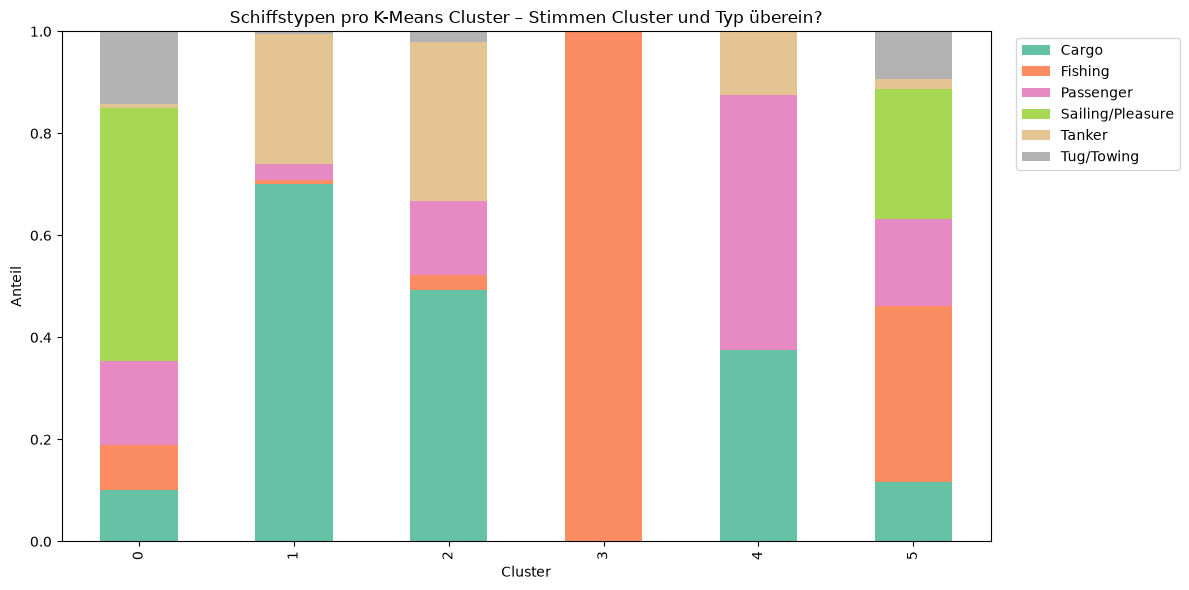

In [39]:
# Cluster vs. gemeldeter Schiffstyp: Kreuztabelle
cross = pd.crosstab(agg['KM_Cluster'], agg['ShipCategory'], normalize='index')
print('Anteil der Schiffstypen pro Cluster (normalisiert):')
print(cross.round(2))

fig, ax = plt.subplots(figsize=(12, 6))
cross.plot(kind='bar', stacked=True, ax=ax, colormap='Set2')
ax.set_ylabel('Anteil')
ax.set_xlabel('Cluster')
ax.set_title('Schiffstypen pro K-Means Cluster – Stimmen Cluster und Typ überein?')
ax.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [40]:
# Konkrete Verdachtsfälle analysieren

# Cargo-Schiffe die sich wie Fischer verhalten (>30% Fishing-Status)
suspect_cargo = agg[(agg['ShipCategory'] == 'Cargo') & (agg['NavStatus_Fishing'] > 0.3)]
print(f'Verdächtig: {len(suspect_cargo)} Cargo-Schiffe mit >30% Fishing-Status')
if len(suspect_cargo) > 0:
    print(suspect_cargo[['MMSI', 'Length', 'Width', 'SOG_mean', 'NavStatus_Fishing',
                         'COG_std', 'Dist_nearest_port_km', 'Anomaly_Sum']].to_string(index=False))

print()

# Fischer die nie fischen (<5% Fishing-Status)
suspect_fish = agg[(agg['ShipCategory'] == 'Fishing') & (agg['NavStatus_Fishing'] < 0.05)]
print(f'Verdächtig: {len(suspect_fish)} Fishing-Schiffe mit <5% Fishing-Status')
if len(suspect_fish) > 0:
    print(suspect_fish[['MMSI', 'Length', 'Width', 'SOG_mean', 'NavStatus_Fishing',
                         'COG_std', 'Dist_nearest_port_km', 'Anomaly_Sum']].to_string(index=False))

print()

# Kleine "Cargo"-Schiffe (Length < 50m)
suspect_small = agg[(agg['ShipCategory'] == 'Cargo') & (agg['Length'] < 50) & (agg['Length'] > 0)]
print(f'Auffällig: {len(suspect_small)} Cargo-Schiffe unter 50m Länge (untypisch klein)')

Verdächtig: 0 Cargo-Schiffe mit >30% Fishing-Status

Verdächtig: 198 Fishing-Schiffe mit <5% Fishing-Status
     MMSI  Length  Width  SOG_mean  NavStatus_Fishing      COG_std  Dist_nearest_port_km  Anomaly_Sum
205198000    38.0    8.0  0.000000                0.0 7.115571e-15            136.689195            0
211325510    53.0   11.0  0.000000                0.0 0.000000e+00             16.707526            0
211363300    38.0    9.0  0.000000                0.0 0.000000e+00             80.374421            0
211364320    37.0    7.0  0.000304                0.0 2.846500e-14             80.441774            0
211364330    36.0   10.0  0.000000                0.0 5.693808e-14             80.367612            0
211410690    50.0   10.0  0.016157                0.0 1.623419e+02             81.391081            0
211413470    44.0   10.0  0.002098                0.0 1.084696e+02             80.400021            0
211452000    23.0    6.0  0.000000                0.0 8.735528e+01          

Cluster-Profile:
  Cluster 0: Sailing/Pleasure (50%) — Mischcluster
  Cluster 1: Cargo (70%) — eindeutig
  Cluster 2: Cargo (49%) — Mischcluster
  Cluster 3: Fishing (100%) — eindeutig
  Cluster 4: Passenger (50%) — Mischcluster
  Cluster 5: Fishing (34%) — Mischcluster

Validierung der 44 Consensus-Anomalien
Typ passt zum Cluster:           19 Schiffe
Typ passt NICHT zum Cluster:     25 Schiffe

--- Aufschlüsselung der 25 Mismatches: ---
  In eindeutigen Clustern (>=70%):   11 — starker Verdacht
  In Mischclustern (<70%):           14 — schwächerer Verdacht

--- 11 Mismatches in eindeutigen Clustern (stärkster Verdacht): ---
     MMSI ShipCategory  KM_Cluster Cluster_Typ  Length  Width  SOG_mean  Anomaly_Sum
218162000      Fishing           1       Cargo    37.0   10.0  8.966212            3
241424000       Tanker           1       Cargo   290.0   46.0 16.727170            2
241649000       Tanker           1       Cargo   274.0   48.0 11.672000            2
249857000       Tanker    

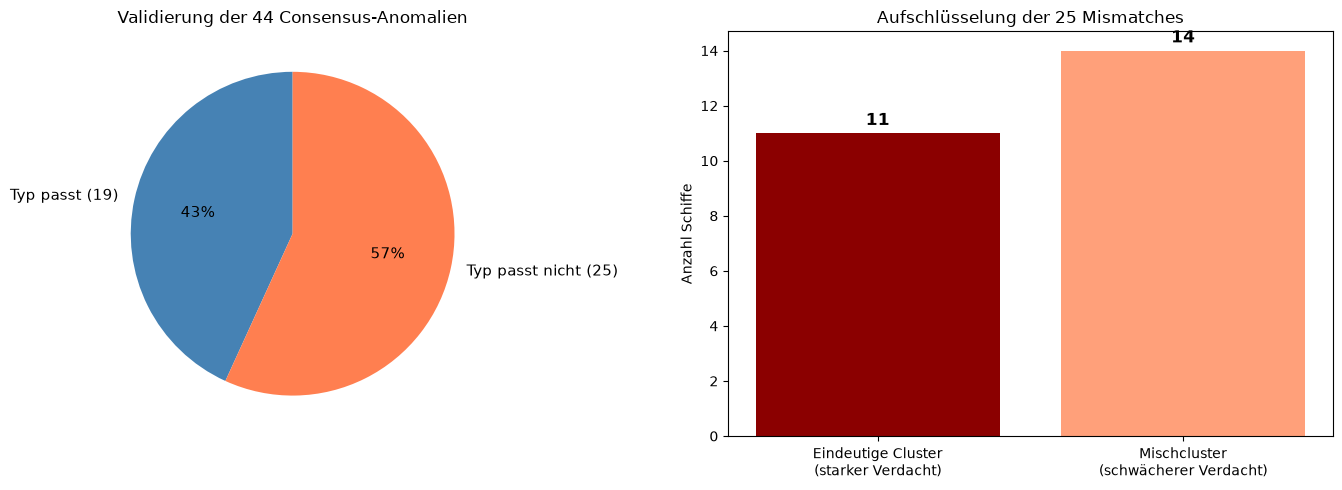

In [41]:
# Validierung: Stimmt der gemeldete Schiffstyp mit dem Cluster-Profil überein?

# Für jedes Cluster: dominanter Typ und dessen Anteil
cluster_dominant = {}
cluster_purity = {}
for c in sorted(agg['KM_Cluster'].unique()):
    counts = agg[agg['KM_Cluster'] == c]['ShipCategory'].value_counts(normalize=True)
    cluster_dominant[c] = counts.index[0]
    cluster_purity[c] = counts.iloc[0]

print("Cluster-Profile:")
for c in sorted(cluster_dominant.keys()):
    purity = cluster_purity[c]
    label = "eindeutig" if purity >= 0.7 else "Mischcluster"
    print(f"  Cluster {c}: {cluster_dominant[c]} ({purity:.0%}) — {label}")

# Für die 44 Consensus-Anomalien prüfen: Passt der gemeldete Typ zum Cluster?
consensus = agg[agg['Anomaly_Sum'] >= 2].copy()
consensus['Cluster_Typ'] = consensus['KM_Cluster'].map(cluster_dominant)
consensus['Cluster_Reinheit'] = consensus['KM_Cluster'].map(cluster_purity)
consensus['Typ_Match'] = consensus['ShipCategory'] == consensus['Cluster_Typ']
consensus['Cluster_Eindeutig'] = consensus['Cluster_Reinheit'] >= 0.7

n_match = consensus['Typ_Match'].sum()
n_mismatch = len(consensus) - n_match

print(f"\n{'='*60}")
print(f"Validierung der {len(consensus)} Consensus-Anomalien")
print(f"{'='*60}")
print(f"Typ passt zum Cluster:          {n_match:>3} Schiffe")
print(f"Typ passt NICHT zum Cluster:    {n_mismatch:>3} Schiffe")

# Aufschlüsselung der Mismatches nach Cluster-Qualität
mismatch = consensus[~consensus['Typ_Match']]
mm_klar = mismatch[mismatch['Cluster_Eindeutig']]
mm_misch = mismatch[~mismatch['Cluster_Eindeutig']]

print(f"\n--- Aufschlüsselung der {n_mismatch} Mismatches: ---")
print(f"  In eindeutigen Clustern (>=70%):  {len(mm_klar):>3} — starker Verdacht")
print(f"  In Mischclustern (<70%):          {len(mm_misch):>3} — schwächerer Verdacht")

if len(mm_klar) > 0:
    print(f"\n--- {len(mm_klar)} Mismatches in eindeutigen Clustern (stärkster Verdacht): ---")
    print(mm_klar[['MMSI', 'ShipCategory', 'KM_Cluster', 'Cluster_Typ', 
                    'Length', 'Width', 'SOG_mean', 'Anomaly_Sum']].to_string(index=False))

if len(mm_misch) > 0:
    print(f"\n--- {len(mm_misch)} Mismatches in Mischclustern (schwächerer Verdacht): ---")
    print(mm_misch[['MMSI', 'ShipCategory', 'KM_Cluster', 'Cluster_Typ',
                     'Length', 'Width', 'SOG_mean', 'Anomaly_Sum']].to_string(index=False))

# Visualisierung
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Links: Match vs Mismatch
labels_pie = [f'Typ passt ({n_match})', f'Typ passt nicht ({n_mismatch})']
axes[0].pie([n_match, n_mismatch], labels=labels_pie, colors=['steelblue', 'coral'],
            autopct='%1.0f%%', startangle=90, textprops={'fontsize': 11})
axes[0].set_title(f'Validierung der {len(consensus)} Consensus-Anomalien')

# Rechts: Mismatches aufgeschlüsselt
labels_bar = ['Eindeutige Cluster\n(starker Verdacht)', 'Mischcluster\n(schwächerer Verdacht)']
bars = axes[1].bar(labels_bar, [len(mm_klar), len(mm_misch)], color=['darkred', 'lightsalmon'])
axes[1].set_ylabel('Anzahl Schiffe')
axes[1].set_title(f'Aufschlüsselung der {n_mismatch} Mismatches')
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
                 f'{int(bar.get_height())}', ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

**Zusatzanalyse: Nur fahrende Schiffe (SOG > 0,5 Knoten)**

Über 50% der Schiffe stehen still (Neujahrstag). Ein stehendes Fischerboot und ein stehendes Segelboot
sehen in den Features fast identisch aus, was zu den Mischclustern beiträgt. Hier testen wir,
ob die Cluster eindeutiger werden, wenn wir nur fahrende Schiffe betrachten.

Fahrende Schiffe (SOG_mean > 0.5): 275 von 1394
Schiffstypen:
ShipCategory
Cargo               175
Tanker               68
Passenger            16
Fishing               7
Sailing/Pleasure      5
Tug/Towing            4
Name: count, dtype: int64



Silhouette Score (nur fahrende): 0.2531
Silhouette Score (alle Schiffe): 0.2570
Verbesserung: -0.0039



Cluster-Zusammensetzung (nur fahrende Schiffe):
ShipCategory       Cargo  Fishing  Passenger  Sailing/Pleasure  Tanker  \
KM_Cluster_Moving                                                        
0                   0.80     0.00       0.01              0.00    0.18   
1                   0.24     0.35       0.06              0.29    0.00   
2                   0.63     0.01       0.00              0.00    0.33   
3                   0.23     0.00       0.62              0.00    0.15   
4                   1.00     0.00       0.00              0.00    0.00   
5                   0.59     0.00       0.09              0.00    0.32   

ShipCategory       Tug/Towing  
KM_Cluster_Moving              
0                        0.01  
1                        0.06  
2                        0.02  
3                        0.00  
4                        0.00  
5                        0.00  

Dominanter Typ pro Cluster:
  Cluster 0 (n=91): Cargo (80%)
  Cluster 1 (n=17): Fishing (35%)
  Cluste

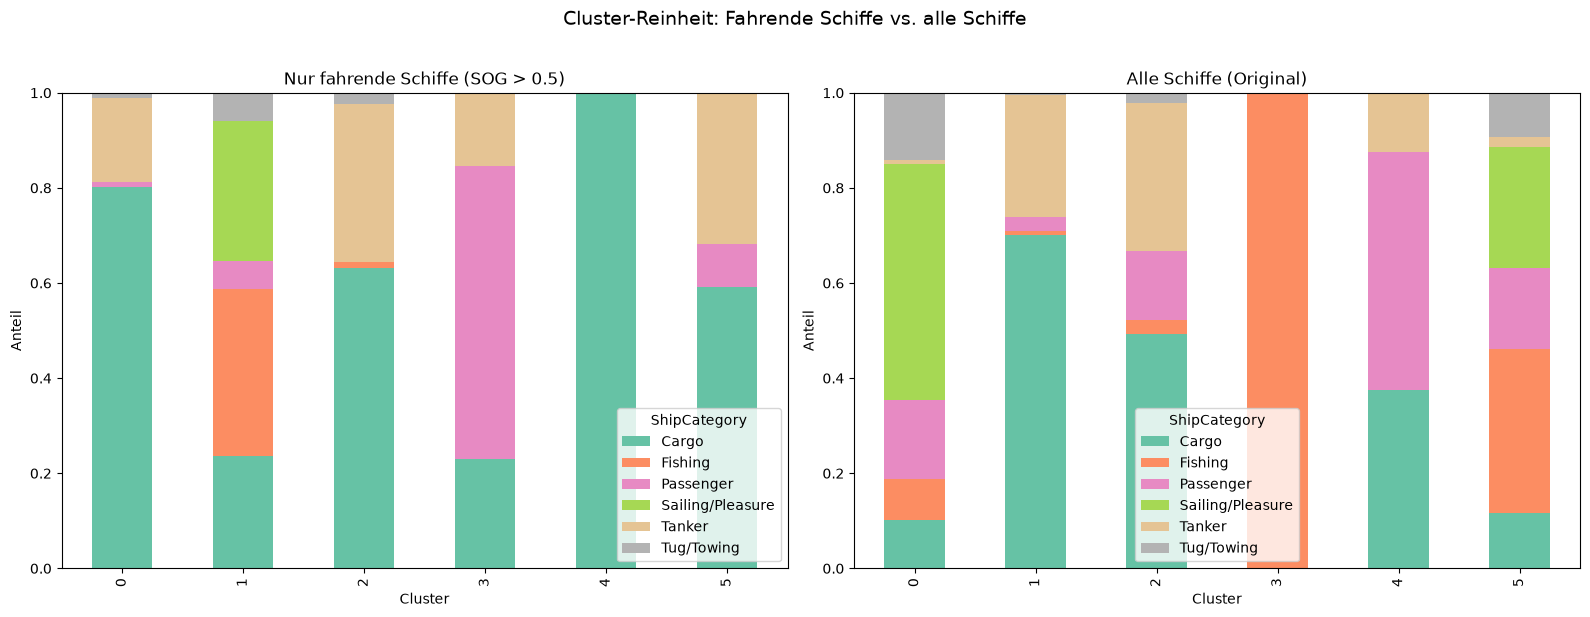

In [42]:
# Zusatzanalyse: Nur fahrende Schiffe (SOG > 0.5 Knoten)
agg_moving = agg[agg['SOG_mean'] > 0.5].copy()
print(f"Fahrende Schiffe (SOG_mean > 0.5): {len(agg_moving)} von {len(agg)}")
print(f"Schiffstypen:\n{agg_moving['ShipCategory'].value_counts()}\n")

# Skalieren und K-Means mit k=6
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_moving = StandardScaler().fit_transform(agg_moving[features])
km_moving = KMeans(n_clusters=6, init='k-means++', n_init=30, max_iter=300, random_state=42)
agg_moving['KM_Cluster_Moving'] = km_moving.fit_predict(X_moving)

sil_moving = silhouette_score(X_moving, agg_moving['KM_Cluster_Moving'])
print(f"Silhouette Score (nur fahrende): {sil_moving:.4f}")
print(f"Silhouette Score (alle Schiffe): {sil_km:.4f}")
print(f"Verbesserung: {'+' if sil_moving > sil_km else ''}{sil_moving - sil_km:.4f}\n")

# Cluster-Zusammensetzung
cross_moving = pd.crosstab(agg_moving['KM_Cluster_Moving'], agg_moving['ShipCategory'], normalize='index')
print("Cluster-Zusammensetzung (nur fahrende Schiffe):")
print(cross_moving.round(2))

# Dominanter Typ pro Cluster mit Anteil
print("\nDominanter Typ pro Cluster:")
for c in sorted(agg_moving['KM_Cluster_Moving'].unique()):
    cluster_data = agg_moving[agg_moving['KM_Cluster_Moving'] == c]
    dom_type = cluster_data['ShipCategory'].value_counts().index[0]
    dom_pct = cluster_data['ShipCategory'].value_counts(normalize=True).iloc[0]
    print(f"  Cluster {c} (n={len(cluster_data)}): {dom_type} ({dom_pct:.0%})")

# Visualisierung
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cross_moving.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2')
axes[0].set_title('Nur fahrende Schiffe (SOG > 0.5)')
axes[0].set_ylabel('Anteil')
axes[0].set_xlabel('Cluster')

# Zum Vergleich: alle Schiffe
cross_all = pd.crosstab(agg['KM_Cluster'], agg['ShipCategory'], normalize='index')
cross_all.plot(kind='bar', stacked=True, ax=axes[1], colormap='Set2')
axes[1].set_title('Alle Schiffe (Original)')
axes[1].set_ylabel('Anteil')
axes[1].set_xlabel('Cluster')

plt.suptitle('Cluster-Reinheit: Fahrende Schiffe vs. alle Schiffe', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Einordnung:** Die 198 Fischer ohne Fishing-Status klingen erstmal viel, aber unsere Daten decken nur ca. eine Stunde ab (01.01.2026, Neujahr). In der Zeit kann ein Fischer im Hafen liegen, auf dem Weg zum Fanggebiet sein oder einfach Pause machen — das heißt nicht automatisch, dass der Typ falsch gemeldet ist. Spannender sind die Fälle wo auch die Modelle anschlagen (Anomaly_Sum ≥ 2), weil da zusätzlich das restliche Verhalten nicht zum Typ passt.

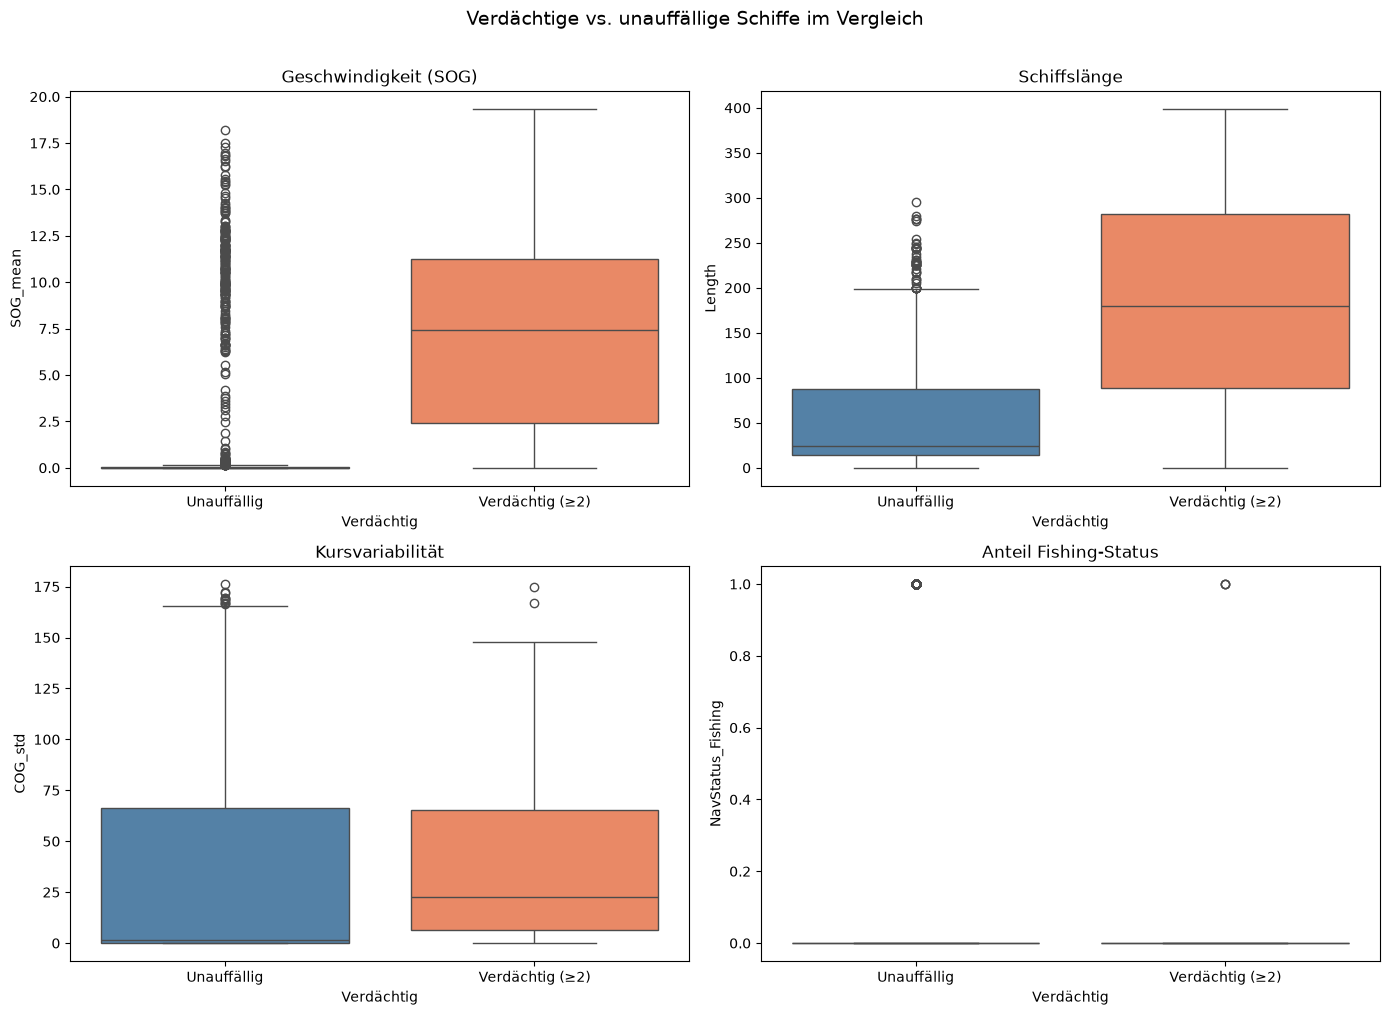

In [43]:
# Auffällige vs. unauffällige Schiffe
agg['Verdächtig'] = (agg['Anomaly_Sum'] >= 2).map({True: 'Verdächtig (≥2)', False: 'Unauffällig'})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=agg, x='Verdächtig', y='SOG_mean', ax=axes[0,0], hue='Verdächtig', palette=['steelblue', 'coral'], legend=False)
axes[0,0].set_title('Geschwindigkeit (SOG)')

sns.boxplot(data=agg, x='Verdächtig', y='Length', ax=axes[0,1], hue='Verdächtig', palette=['steelblue', 'coral'], legend=False)
axes[0,1].set_title('Schiffslänge')

sns.boxplot(data=agg, x='Verdächtig', y='COG_std', ax=axes[1,0], hue='Verdächtig', palette=['steelblue', 'coral'], legend=False)
axes[1,0].set_title('Kursvariabilität')

sns.boxplot(data=agg, x='Verdächtig', y='NavStatus_Fishing', ax=axes[1,1], hue='Verdächtig', palette=['steelblue', 'coral'], legend=False)
axes[1,1].set_title('Anteil Fishing-Status')

plt.suptitle('Verdächtige vs. unauffällige Schiffe im Vergleich', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Reflexion und Ausblick

Die drei Methoden finden Schiffe deren Verhalten nicht zum gemeldeten Typ passt.
Der Consensus-Ansatz (mindestens 2 von 3 Methoden müssen zustimmen) ist eine in der
Anomalie-Erkennung etablierte Technik ("Ensemble Anomaly Detection"), ähnlich wie
Random Forest mehrere Decision Trees kombiniert. Dadurch werden die Ergebnisse robuster
und False Positives reduziert.

**Was gut funktioniert hat:**
- K-Means trennt die Schiffstypen sinnvoll (Cluster 3 = 100% Fishing, Cluster 1 = Cargo/Tanker)
- DBSCAN liefert mit nur 1,6% Noise ein sauberes Ergebnis trotz 16 Dimensionen
- Die Feature-Importance-Analyse (Spearman-Korrelation mit dem IF Anomaly Score) zeigt,
  dass Geschwindigkeit und physische Merkmale die stärksten Indikatoren sind
- Die externen Hafendaten bringen kaum was (Rang 15-16 von 16 bei Feature Importance) —
  auch das ist ein Ergebnis

**Was nicht optimal ist:**
- Das Zeitfenster von einer Stunde ist kurz — manche Schiffe zeigen da vielleicht noch
  gar nicht ihr typisches Verhalten (z.B. Fischer die gerade erst auslaufen)
- Die 5% Contamination beim Isolation Forest ist eine Annahme, kein gemessener Wert
- Bei mehr Dimensionen könnte man vorher PCA zur Dimensionsreduktion einsetzen, was
  besonders DBSCAN helfen würde

**Eigene Erweiterungen:**
- Isolation Forest als dritte Methode (basiert auf Decision Trees)
- Consensus-Ansatz zur Kombination aller drei Methoden
- Feature-Importance-Analyse per Spearman-Korrelation
- Vergleich mit vs. ohne externe Hafendaten

**Mögliche nächste Schritte:**
- Längere Beobachtungszeiträume (mehrere Tage/Wochen)
- Bessere externe Daten (Fischereizonen, Schifffahrtsrouten)
- PCA-Dimensionsreduktion vor DBSCAN
- Semi-Supervised Learning wenn verifizierte Labels für einige Schiffe vorliegen
